In [1]:
%pip install -q lightgbm

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import time
from google.colab import files
import zipfile
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from scipy.stats import spearmanr
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

## 1. Load data

In [3]:
uploaded = files.upload()

Saving test_with_RUL.csv to test_with_RUL.csv
Saving train_with_RUL.csv to train_with_RUL.csv


In [4]:
# Load datasets
train_df = pd.read_csv("/content/train_with_RUL.csv")
test_df = pd.read_csv("/content/test_with_RUL.csv")

# Display basic information
print("TRAIN DATA")
print("Shape:", train_df.shape)
print("Missing values:", train_df.isna().sum().sum())

print("\nTEST DATA")
print("Shape:", test_df.shape)
print("Missing values:", test_df.isna().sum().sum())

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nSubsets in training data:")
print(train_df["subset"].value_counts().sort_index())

print("\nSubsets in test data:")
print(test_df["subset"].value_counts().sort_index())

TRAIN DATA
Shape: (160359, 29)
Missing values: 0

TEST DATA
Shape: (104897, 29)
Missing values: 0

Train columns:
['subset', 'unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'RUL', 'RUL_CAPPED']

Test columns:
['subset', 'unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'RUL', 'RUL_CAPPED']

Subsets in training data:
subset
FD001    20631
FD002    53759
FD003    24720
FD004    61249
Name: count, dtype: int64

Subsets in test data:
subset
FD001    13096
FD

## 2. Features, targets and engine-level train/validation split

In [5]:
# 1. Define feature columns
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

feature_columns = [
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3"
] + sensor_columns

# 2. Prepare model inputs
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# 3. Prepare the two target options
y_train_rul = train_df["RUL"].copy()
y_test_rul = test_df["RUL"].copy()

y_train_capped = train_df["RUL_CAPPED"].copy()
y_test_capped = test_df["RUL_CAPPED"].copy()

# 4. Verify the data
print("Number of features:", len(feature_columns))
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTarget shapes:")
print("Original RUL - train:", y_train_rul.shape)
print("Original RUL - test:", y_test_rul.shape)
print("Capped RUL - train:", y_train_capped.shape)
print("Capped RUL - test:", y_test_capped.shape)

print("\nMissing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

print("\nFeatures used:")
print(feature_columns)

Number of features: 25
X_train shape: (160359, 25)
X_test shape: (104897, 25)

Target shapes:
Original RUL - train: (160359,)
Original RUL - test: (104897,)
Capped RUL - train: (160359,)
Capped RUL - test: (104897,)

Missing values in X_train: 0
Missing values in X_test: 0

Features used:
['cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [6]:
# Keep each engine entirely in either training or validation
groups = train_df["subset"] + "_" + train_df["unit"].astype(str)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train_rul, groups=groups)
)

# Training and validation features
X_train_split = X_train.iloc[train_idx].copy()
X_val = X_train.iloc[val_idx].copy()

# Both target options
y_train_rul_split = y_train_rul.iloc[train_idx].copy()
y_val_rul = y_train_rul.iloc[val_idx].copy()

y_train_capped_split = y_train_capped.iloc[train_idx].copy()
y_val_capped = y_train_capped.iloc[val_idx].copy()

# Verify the split
train_engines = set(groups.iloc[train_idx])
val_engines = set(groups.iloc[val_idx])

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))
print("Engines shared between splits:", len(train_engines & val_engines))
print("Training subsets:", sorted(train_df.iloc[train_idx]["subset"].unique()))
print("Validation subsets:", sorted(train_df.iloc[val_idx]["subset"].unique()))

Training rows: 129029
Validation rows: 31330
Training engines: 567
Validation engines: 142
Engines shared between splits: 0
Training subsets: ['FD001', 'FD002', 'FD003', 'FD004']
Validation subsets: ['FD001', 'FD002', 'FD003', 'FD004']


In [7]:
# Compare RUL distribution across training and validation
def summarize_rul(y, name):
    return pd.Series({
        "Rows": len(y),
        "Min": y.min(),
        "Max": y.max(),
        "Mean": y.mean(),
        "Median": y.median(),
        "Std": y.std()
    }, name=name)

rul_distribution = pd.concat([
    summarize_rul(y_train_rul_split, "Training"),
    summarize_rul(y_val_rul, "Validation")
], axis=1).T

display(rul_distribution.round(2))

,Rows,Min,Max,Mean,Median,Std
Training,129029.0,0.0,542.0,123.15,113.0,83.98
Validation,31330.0,0.0,493.0,118.95,110.0,81.60


In [8]:
# Compare engine counts by subset
train_engine_counts = (
    train_df.iloc[train_idx]
    .groupby("subset")["unit"]
    .nunique()
    .rename("Training engines")
)

val_engine_counts = (
    train_df.iloc[val_idx]
    .groupby("subset")["unit"]
    .nunique()
    .rename("Validation engines")
)

engine_distribution = pd.concat(
    [train_engine_counts, val_engine_counts],
    axis=1
)

display(engine_distribution)

,Training engines,Validation engines
subset,,
FD001,74,26
FD002,199,61
FD003,84,16
FD004,210,39


In [9]:
train_indices = []
val_indices = []

for subset in sorted(train_df["subset"].unique()):
    subset_indices = np.where(
        train_df["subset"].to_numpy() == subset
    )[0]

    subset_groups = (
        train_df.iloc[subset_indices]["unit"].to_numpy()
    )

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=42
    )

    tr, va = next(
        splitter.split(subset_indices, groups=subset_groups)
    )

    train_indices.extend(subset_indices[tr])
    val_indices.extend(subset_indices[va])

train_idx = np.array(sorted(train_indices))
val_idx = np.array(sorted(val_indices))

# Recreate features and targets for the new split
X_train_split = X_train.iloc[train_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_train_rul_split = y_train_rul.iloc[train_idx].copy()
y_val_rul = y_train_rul.iloc[val_idx].copy()

y_train_capped_split = y_train_capped.iloc[train_idx].copy()
y_val_capped = y_train_capped.iloc[val_idx].copy()

# Verify engine separation
groups = train_df["subset"] + "_" + train_df["unit"].astype(str)

train_engines = set(groups.iloc[train_idx])
val_engines = set(groups.iloc[val_idx])

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Shared engines:", len(train_engines & val_engines))

display(pd.DataFrame({
    "Training engines": train_df.iloc[train_idx].groupby("subset")["unit"].nunique(),
    "Validation engines": train_df.iloc[val_idx].groupby("subset")["unit"].nunique()
}))

Training rows: 129331
Validation rows: 31028
Shared engines: 0


,Training engines,Validation engines
subset,,
FD001,80,20
FD002,208,52
FD003,80,20
FD004,199,50


## 3. Model comparison (XGBoost vs Random Forest vs LightGBM vs BiLSTM)

Setup

In [10]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

LOOKBACK = 30
EPOCHS = 10
BATCH_SIZE = 256

# Same train/validation data for all models
X_tr = X_train_split.copy()
X_va = X_val.copy()

targets = {
    "RUL": (
        y_train_rul_split.to_numpy(),
        y_val_rul.to_numpy()
    ),
    "RUL_CAPPED": (
        y_train_capped_split.to_numpy(),
        y_val_capped.to_numpy()
    )
}

# Store results and trained models
results = []
trained_models = {}

print("Common setup completed.")
print("Training shape:", X_tr.shape)
print("Validation shape:", X_va.shape)

Common setup completed.
Training shape: (129331, 25)
Validation shape: (31028, 25)


Random forest model

In [11]:
for target_name, (y_train_target, y_val_target) in targets.items():

    print(f"\nRandom Forest - {target_name}")

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(X_tr, y_train_target)

    predictions = model.predict(X_va)

    mae = mean_absolute_error(y_val_target, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_target, predictions))

    results.append({
        "Target": target_name,
        "Model": "Random Forest",
        "MAE": mae,
        "RMSE": rmse,
        "Training_Time_sec": time.time() - start_time
    })

    trained_models[(target_name, "Random Forest")] = model

    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")


Random Forest - RUL
MAE: 32.302
RMSE: 46.281

Random Forest - RUL_CAPPED
MAE: 11.031
RMSE: 16.767


XGBoost Model

In [12]:
for target_name, (y_train_target, y_val_target) in targets.items():

    print(f"\nXGBoost - {target_name}")

    model = XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        early_stopping_rounds=30,
        random_state=SEED,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_tr,
        y_train_target,
        eval_set=[(X_va, y_val_target)],
        verbose=False
    )

    predictions = model.predict(X_va)

    mae = mean_absolute_error(y_val_target, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_target, predictions))

    results.append({
        "Target": target_name,
        "Model": "XGBoost",
        "MAE": mae,
        "RMSE": rmse,
        "Training_Time_sec": time.time() - start_time
    })

    trained_models[(target_name, "XGBoost")] = model

    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")


XGBoost - RUL
MAE: 32.288
RMSE: 45.750

XGBoost - RUL_CAPPED
MAE: 10.848
RMSE: 16.435


LightGBM model

In [13]:
for target_name, (y_train_target, y_val_target) in targets.items():

    print(f"\nLightGBM - {target_name}")

    model = LGBMRegressor(
        n_estimators=500,
        max_depth=-1,
        num_leaves=31,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        verbosity=-1,
        random_state=SEED,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(X_tr, y_train_target)

    predictions = model.predict(X_va)

    mae = mean_absolute_error(y_val_target, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_target, predictions))

    results.append({
        "Target": target_name,
        "Model": "LightGBM",
        "MAE": mae,
        "RMSE": rmse,
        "Training_Time_sec": time.time() - start_time
    })

    trained_models[(target_name, "LightGBM")] = model

    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")


LightGBM - RUL
MAE: 32.437
RMSE: 46.119

LightGBM - RUL_CAPPED
MAE: 11.171
RMSE: 16.718


LSTM model

In [14]:
def build_sequences(frame, indices, scaler, lookback=30):

    selected = frame.iloc[indices].copy()
    selected["_original_index"] = indices

    selected = selected.sort_values(
        ["subset", "unit", "cycle"]
    )

    feature_array = scaler.transform(
        selected[feature_columns]
    ).astype(np.float32)

    X_sequences = []
    original_indices = []

    for _, group in selected.groupby(
        ["subset", "unit"], sort=False
    ):

        positions = group.index.to_numpy()
        row_indices = group["_original_index"].to_numpy()

        group_positions = selected.index.get_indexer(positions)
        group_features = feature_array[group_positions]

        for j in range(len(group_features)):

            start = max(0, j - lookback + 1)
            window = group_features[start:j + 1]

            if len(window) < lookback:

                padding = np.repeat(
                    window[[0]],
                    lookback - len(window),
                    axis=0
                )

                window = np.concatenate(
                    [padding, window],
                    axis=0
                )

            X_sequences.append(window)
            original_indices.append(row_indices[j])

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(original_indices)
    )


# Scale using training data only
scaler = StandardScaler()
scaler.fit(X_tr)

X_seq_train, seq_train_indices = build_sequences(
    train_df, train_idx, scaler, LOOKBACK
)

X_seq_val, seq_val_indices = build_sequences(
    train_df, val_idx, scaler, LOOKBACK
)

print("LSTM training sequences:", X_seq_train.shape)
print("LSTM validation sequences:", X_seq_val.shape)

LSTM training sequences: (129331, 30, 25)
LSTM validation sequences: (31028, 30, 25)


In [15]:
def make_lstm(input_shape):

    model = Sequential([
        Input(shape=input_shape),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model


for target_name, (y_train_target, y_val_target) in targets.items():

    print(f"\nLSTM - {target_name}")

    # Align targets with sequence order
    y_train_seq = train_df.iloc[
        seq_train_indices
    ][target_name].to_numpy(dtype=np.float32)

    y_val_seq = train_df.iloc[
        seq_val_indices
    ][target_name].to_numpy(dtype=np.float32)

    # Create LSTM model
    lstm = make_lstm(
        (LOOKBACK, len(feature_columns))
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    # Train model
    lstm.fit(
        X_seq_train,
        y_train_seq,
        validation_data=(X_seq_val, y_val_seq),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    # Predictions
    predictions = lstm.predict(
        X_seq_val,
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel()

    # Evaluation
    mae = mean_absolute_error(
        y_val_seq, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val_seq, predictions)
    )

    # Store results
    results.append({
        "Target": target_name,
        "Model": "LSTM",
        "MAE": mae,
        "RMSE": rmse,
        "Training_Time_sec": time.time() - start_time
    })

    trained_models[(target_name, "LSTM")] = lstm

    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")


LSTM - RUL
Epoch 1/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 12554.7871 - mae: 85.9281 - val_loss: 6464.7129 - val_mae: 64.1294
Epoch 2/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 4752.0449 - mae: 50.2720 - val_loss: 2741.8271 - val_mae: 38.8846
Epoch 3/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 2850.0100 - mae: 38.2605 - val_loss: 2534.5564 - val_mae: 35.9910
Epoch 4/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2610.4451 - mae: 36.5136 - val_loss: 2273.4753 - val_mae: 33.4003
Epoch 5/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 2520.7493 - mae: 35.7452 - val_loss: 2261.0320 - val_mae: 33.1508
Epoch 6/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 2454.7683 - mae: 35.2064 - val_loss: 2224.9038 - val_mae: 33.0466
Epoch 7/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2416.9624 - mae: 34.8044 - val_loss: 2228.7185 - val_mae: 32.5950
Epoch 8/10
506/506 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 2388.7451 - mae: 34.4705 - val_loss: 2198.864

Final Model Comparison

In [16]:
results_df = pd.DataFrame(results).sort_values(
    ["Target", "MAE"]
).reset_index(drop=True)

print("FINAL VALIDATION COMPARISON")

display(results_df.round(3))

FINAL VALIDATION COMPARISON


,Target,Model,MAE,RMSE,Training_Time_sec
0,RUL,XGBoost,32.288,45.750,5.305
1,RUL,Random Forest,32.302,46.281,184.576
2,RUL,LightGBM,32.437,46.119,5.667
3,RUL,LSTM,32.625,46.892,47.115
4,RUL_CAPPED,XGBoost,10.848,16.435,14.341
5,RUL_CAPPED,Random Forest,11.031,16.767,198.942
6,RUL_CAPPED,LightGBM,11.171,16.718,7.137
7,RUL_CAPPED,LSTM,11.668,17.106,44.921


Because the XGboost the highest one we chose it

In [17]:
# Validation predictions from the trained XGBoost model
best_model = trained_models[("RUL_CAPPED", "XGBoost")]
val_predictions = best_model.predict(X_val)

# Build validation results
validation_results = train_df.iloc[val_idx][
    ["subset", "unit", "cycle", "RUL", "RUL_CAPPED"]
].copy()

validation_results["Predicted_RUL_CAPPED"] = val_predictions

# Evaluate separately for each subset
rows = []

for subset, group in validation_results.groupby("subset"):
    mae = mean_absolute_error(
        group["RUL_CAPPED"],
        group["Predicted_RUL_CAPPED"]
    )
    rmse = np.sqrt(mean_squared_error(
        group["RUL_CAPPED"],
        group["Predicted_RUL_CAPPED"]
    ))

    rows.append({
        "Subset": subset,
        "Rows": len(group),
        "MAE": mae,
        "RMSE": rmse
    })

subset_results = pd.DataFrame(rows)

display(subset_results.round(3))

,Subset,Rows,MAE,RMSE
0,FD001,4070,10.348,15.210
1,FD002,10295,11.132,16.282
2,FD003,4708,7.239,11.640
3,FD004,11955,12.194,18.455


In [18]:
final_candidate = trained_models[("RUL_CAPPED", "XGBoost")]

test_sorted = test_df.sort_values(
    ["subset", "unit", "cycle"]
).copy()

last_cycles = (
    test_sorted
    .groupby(["subset", "unit"], sort=False)
    .tail(1)
    .copy()
)

X_test_last = last_cycles[feature_columns]

y_true = last_cycles["RUL_CAPPED"].to_numpy()
y_pred = final_candidate.predict(X_test_last)

errors = y_pred - y_true
abs_errors = np.abs(errors)

test_metrics = pd.DataFrame([{
    "Engines": len(last_cycles),
    "MAE": mean_absolute_error(y_true, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    "Within ±10 (%)": np.mean(abs_errors <= 10) * 100,
    "Within ±20 (%)": np.mean(abs_errors <= 20) * 100
}]).round(3)

display(test_metrics)


,Engines,MAE,RMSE,Within ±10 (%),Within ±20 (%)
0,707,11.957,16.82,57.001,79.491


In [19]:
error_analysis = (
    test_df.sort_values(["subset", "unit", "cycle"])
    .groupby(["subset", "unit"], sort=False)
    .tail(1)
    .copy()
)

X_test_last = error_analysis[feature_columns]

model_capped = trained_models[("RUL_CAPPED", "XGBoost")]
predictions = model_capped.predict(X_test_last)

error_analysis["Actual_RUL_CAPPED"] = error_analysis["RUL_CAPPED"]
error_analysis["Predicted_RUL_CAPPED"] = predictions
error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Actual_RUL_CAPPED"]
    - error_analysis["Predicted_RUL_CAPPED"]
)

print(
    "Number of engines with error > 20 cycles:",
    (error_analysis["Absolute_Error"] > 20).sum()
)

display(
    error_analysis[
        [
            "subset", "unit", "cycle",
            "Actual_RUL_CAPPED",
            "Predicted_RUL_CAPPED",
            "Absolute_Error"
        ]
    ]
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)


Number of engines with error > 20 cycles: 145


,subset,unit,cycle,Actual_RUL_CAPPED,Predicted_RUL_CAPPED,Absolute_Error
103892,FD004,240,204,98,23.610001,74.39
82437,FD004,106,148,107,45.930000,61.07
40967,FD002,209,131,23,83.169998,60.17
29482,FD002,121,59,67,119.959999,52.96
49387,FD003,16,126,56,108.589996,52.59
95660,FD004,189,107,56,107.129997,51.13
61965,FD003,93,158,67,116.480003,49.48
30494,FD002,130,141,121,71.570000,49.43
93210,FD004,175,116,123,74.440002,48.56
92066,FD004,166,63,72,119.730003,47.73


In [20]:
error_analysis["Error_Direction"] = np.where(
    error_analysis["Predicted_RUL_CAPPED"]
    > error_analysis["Actual_RUL_CAPPED"],
    "Overestimation",
    "Underestimation"
)

error_summary = (
    error_analysis.groupby("subset")
    .agg(
        Engines=("unit", "nunique"),
        MAE=("Absolute_Error", "mean"),
        Errors_Over_20=(
            "Absolute_Error",
            lambda x: (x > 20).sum()
        ),
        Percent_Over_20=(
            "Absolute_Error",
            lambda x: (x > 20).mean() * 100
        ),
        Maximum_Error=("Absolute_Error", "max")
    )
    .round(2)
)

display(error_summary)

print("\nError direction:")
display(
    error_analysis.groupby(
        ["subset", "Error_Direction"]
    ).size().unstack(fill_value=0)
)


,Engines,MAE,Errors_Over_20,Percent_Over_20,Maximum_Error
subset,,,,,
FD001,100,12.05,23,23.00,47.24
FD002,259,11.77,51,19.69,60.17
FD003,100,12.16,18,18.00,52.59
FD004,248,12.04,53,21.37,74.39



Error direction:


Error_Direction,Overestimation,Underestimation
subset,,
FD001,50,50
FD002,111,148
FD003,56,44
FD004,121,127


## 4. XGBoost enhancement (feature engineering, validation, tuning, final model)

In [21]:
# Selected sensors
selected_sensors = [2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21]

sensor_cols = [f"sensor_{i}" for i in selected_sensors]
all_sensors = [f"sensor_{i}" for i in range(1, 22)]

subsets = ["FD001", "FD002", "FD003", "FD004"]

# Feature engineering settings
windows = (10, 30)
start_cycles = 20
rul_cap = 125
seed = 42

raw_features = (
    ["cycle", "setting_1", "setting_2", "setting_3"]
    + all_sensors
)

print("Settings ready.")
print("Selected sensors:", len(sensor_cols))

Settings ready.
Selected sensors: 14


Prepare Engine Data

In [22]:
# Prepare Engine Data

def prepare_engines(df):

    df = df.copy()

    df["engine_id"] = (
        df["subset"] + "_" + df["unit"].astype(int).astype(str)
    )

    df[all_sensors] = df[all_sensors].astype(float)

    df = df.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    return df


raw_train = prepare_engines(train_df)
raw_test = prepare_engines(test_df)

print("Train:", raw_train.shape)
print("Test:", raw_test.shape)

Train: (160359, 30)
Test: (104897, 30)


Operating Conditions Normalization

In [23]:
# Operating Conditions Normalization

def add_regime(df):

    df = df.copy()

    setting1 = df["setting_1"].round(0).astype(int).astype(str)
    setting2 = df["setting_2"].round(2).astype(str)

    df["regime"] = df["subset"] + "|" + setting1 + "_" + setting2

    return df


def fit_normalizer(df):

    regime_stats = df.groupby("regime")[sensor_cols]
    subset_stats = df.groupby("subset")[sensor_cols]

    normalizer = {
        "regime_mean": regime_stats.mean(),
        "regime_std": regime_stats.std().replace(0, np.nan),
        "subset_mean": subset_stats.mean(),
        "subset_std": subset_stats.std().replace(0, np.nan)
    }

    return normalizer


def normalize_sensors(df, normalizer):

    df = df.copy()

    mean = normalizer["regime_mean"].reindex(df["regime"]).values
    std = normalizer["regime_std"].reindex(df["regime"]).values

    subset_mean = normalizer["subset_mean"].reindex(df["subset"]).values
    subset_std = normalizer["subset_std"].reindex(df["subset"]).values

    mean = np.where(np.isnan(mean), subset_mean, mean)
    std = np.where(np.isnan(std), subset_std, std)

    df[sensor_cols] = np.nan_to_num(
        (df[sensor_cols].values - mean) / std,
        nan=0.0
    )

    return df


# Add operating regimes
raw_train = add_regime(raw_train)
raw_test = add_regime(raw_test)

# Fit using training data only
normalizer = fit_normalizer(raw_train)

print("Operating conditions ready.")

Operating conditions ready.


Feature Engineering

In [24]:
# Feature Engineering

def create_time_features(df):

    df = df.copy()
    engines = df.groupby("engine_id")

    new_features = {}

    for sensor in sensor_cols:

        for window in windows:

            rolling = engines[sensor].rolling(
                window,
                min_periods=1
            )

            # Rolling mean
            new_features[f"{sensor}_mean{window}"] = (
                rolling.mean().reset_index(level=0, drop=True)
            )

            # Rolling standard deviation
            new_features[f"{sensor}_std{window}"] = (
                rolling.std()
                .reset_index(level=0, drop=True)
                .fillna(0)
            )

            # Change over time
            change = (
                df[sensor] -
                engines[sensor].shift(window - 1)
            )

            first_value = engines[sensor].transform("first")

            new_features[f"{sensor}_delta{window}"] = (
                change.fillna(df[sensor] - first_value)
            )

        # Difference from the engine's starting condition
        start_mean = engines[sensor].transform(
            lambda x: (
                x.expanding()
                .mean()
                .where(np.arange(len(x)) < start_cycles)
                .ffill()
            )
        )

        new_features[f"{sensor}_vs_start"] = (
            df[sensor] - start_mean
        )

        # Rolling mean of last 5 cycles
        new_features[f"{sensor}_mean5"] = (
            engines[sensor]
            .rolling(5, min_periods=1)
            .mean()
            .reset_index(level=0, drop=True)
        )

    df = pd.concat(
        [df, pd.DataFrame(new_features)],
        axis=1
    )

    return df

Build Enhanced Dataset

In [25]:
# Build Enhanced Dataset

def get_feature_columns(use_mean5=False):

    features = []

    for sensor in sensor_cols:

        features.append(sensor)

        for window in windows:

            features.extend([
                f"{sensor}_mean{window}",
                f"{sensor}_std{window}",
                f"{sensor}_delta{window}"
            ])

        features.append(f"{sensor}_vs_start")

        if use_mean5:
            features.append(f"{sensor}_mean5")

    features.append("cycle")

    features.extend(
        [f"is_{subset}" for subset in subsets]
    )

    return features


def build_features(df, normalizer):

    df = normalize_sensors(df, normalizer)
    df = create_time_features(df)

    for subset in subsets:
        df[f"is_{subset}"] = (
            df["subset"] == subset
        ).astype(int)

    return df


train_data = build_features(raw_train, normalizer)
test_data = build_features(raw_test, normalizer)

print("Enhanced train:", train_data.shape)
print("Enhanced test:", test_data.shape)

print("Original features:", len(raw_features))
print("Enhanced features:", len(get_feature_columns()))
print("Enhanced + Mean5:", len(get_feature_columns(True)))

Enhanced train: (160359, 147)
Enhanced test: (104897, 147)
Original features: 25
Enhanced features: 117
Enhanced + Mean5: 131


Validation Setup

In [26]:
# Validation Setup

cut_fractions = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


def get_cut_mask(df):

    max_cycles = df.groupby("engine_id")["cycle"].transform("max")

    mask = np.zeros(len(df), dtype=bool)

    for fraction in cut_fractions:

        cut_cycle = np.maximum(
            1,
            np.round(fraction * max_cycles).astype(int)
        )

        mask |= (df["cycle"] == cut_cycle).values

    return mask


def calculate_metrics(actual, predicted):

    errors = np.abs(
        np.asarray(actual) - np.asarray(predicted)
    )

    return {
        "MAE": errors.mean(),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Within ±10 (%)": (errors <= 10).mean() * 100,
        "Within ±20 (%)": (errors <= 20).mean() * 100
    }


y_train = train_data["RUL_CAPPED"].to_numpy(dtype=float)

groups = train_data["engine_id"].to_numpy()

cut_mask = get_cut_mask(train_data)

folds = list(
    GroupKFold(n_splits=5).split(
        train_data,
        groups=groups
    )
)

print("Training rows:", len(train_data))
print("Validation cut rows:", cut_mask.sum())
print("Number of folds:", len(folds))

Training rows: 160359
Validation cut rows: 5672
Number of folds: 5


## XGBoost Configurations

In [27]:
# XGBoost Configurations

def create_xgboost(**params):

    settings = {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.7,
        "reg_lambda": 1.0,
        "objective": "reg:squarederror",
        "tree_method": "hist",
        "random_state": seed,
        "n_jobs": -1
    }

    settings.update(params)

    return XGBRegressor(**settings)


notebook_params = {
    "n_estimators": 500,
    "max_depth": 8,
    "learning_rate": 0.05,
    "min_child_weight": 1,
    "colsample_bytree": 0.8
}

proposed_params = {
    "n_estimators": 700,
    "max_depth": 5,
    "learning_rate": 0.03,
    "min_child_weight": 5
}

experiments = [
    ("1 Baseline", "raw", notebook_params),
    ("2 Enhanced features", "enhanced", notebook_params),
    ("3 Enhanced + new parameters", "enhanced", proposed_params),
    ("4 Enhanced + mean5", "enhanced_mean5", proposed_params),
    ("5 Enhanced + depth6", "enhanced", {})
]

train_features = {
    "raw": raw_train[raw_features].to_numpy(),
    "enhanced": train_data[get_feature_columns()].to_numpy(),
    "enhanced_mean5": train_data[get_feature_columns(True)].to_numpy()
}

print("Number of experiments:", len(experiments))

Number of experiments: 5


Model Comparison

In [28]:
# Compare Enhancement Experiments

results = []

for name, feature_set, params in experiments:

    start_time = time.time()

    X = train_features[feature_set]

    predictions = np.zeros(len(y_train))

    for train_idx, val_idx in folds:

        model = create_xgboost(**params)

        model.fit(
            X[train_idx],
            y_train[train_idx]
        )

        predictions[val_idx] = model.predict(X[val_idx])

    predictions = np.clip(predictions, 0, rul_cap)

    cut_metrics = calculate_metrics(
        y_train[cut_mask],
        predictions[cut_mask]
    )

    all_metrics = calculate_metrics(
        y_train,
        predictions
    )

    results.append({
        "Config": name,
        "Features": feature_set,
        **cut_metrics,
        "RMSE (all rows)": all_metrics["RMSE"],
        "Minutes": round((time.time() - start_time) / 60, 1)
    })

    print(f"Finished: {name}")

cv_results = pd.DataFrame(results)

display(cv_results.round(2))

Finished: 1 Baseline
Finished: 2 Enhanced features
Finished: 3 Enhanced + new parameters
Finished: 4 Enhanced + mean5
Finished: 5 Enhanced + depth6


,Config,Features,MAE,RMSE,Within ±10 (%),Within ±20 (%),RMSE (all rows),Minutes
0,1 Baseline,raw,13.28,18.32,53.12,76.02,15.95,0.9
1,2 Enhanced features,enhanced,8.57,12.49,69.62,88.88,10.85,7.6
2,3 Enhanced + new parameters,enhanced,8.94,12.85,67.68,88.40,11.18,3.7
3,4 Enhanced + mean5,enhanced_mean5,8.90,12.83,67.93,88.42,11.19,4.2
4,5 Enhanced + depth6,enhanced,8.80,12.71,68.27,88.50,11.05,4.1


Select Best Model

In [29]:
# Select Best Enhanced Model

enhanced_results = cv_results.iloc[1:]

best_row = enhanced_results.sort_values("RMSE").iloc[0]

best_experiment = next(
    exp for exp in experiments
    if exp[0] == best_row["Config"]
)

best_name, best_features, best_params = best_experiment

print("Selected model:", best_name)
print("Feature set:", best_features)
print("Validation RMSE:", round(best_row["RMSE"], 3))

Selected model: 2 Enhanced features
Feature set: enhanced
Validation RMSE: 12.493


Final Training and Test Evaluation

In [30]:
# Final Training and Test Evaluation

# Last observed cycle of each test engine
last_cycles = (
    test_data
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .copy()
)

actual_rul = last_cycles["RUL_CAPPED"].to_numpy(dtype=float)

test_features = {
    "raw": raw_test.loc[last_cycles.index, raw_features].to_numpy(),
    "enhanced": last_cycles[get_feature_columns()].to_numpy(),
    "enhanced_mean5": last_cycles[get_feature_columns(True)].to_numpy()
}

test_results = []

for label, experiment in [
    ("Baseline", experiments[0]),
    ("Enhanced", best_experiment)
]:

    name, feature_set, params = experiment

    model = create_xgboost(**params)

    model.fit(
        train_features[feature_set],
        y_train
    )

    predicted_rul = np.clip(
        model.predict(test_features[feature_set]),
        0,
        rul_cap
    )

    metrics = calculate_metrics(
        actual_rul,
        predicted_rul
    )

    test_results.append({
        "Model": label,
        **metrics,
        "Errors > 20": int(
            (np.abs(predicted_rul - actual_rul) > 20).sum()
        )
    })

    if label == "Enhanced":
        final_model = model
        final_predictions = predicted_rul

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(3))

,Model,MAE,RMSE,Within ±10 (%),Within ±20 (%),Errors > 20
0,Baseline,12.060,16.862,56.719,79.208,147
1,Enhanced,7.679,11.172,72.702,91.796,58


Save Final Model

In [31]:
# Save Final Enhanced XGBoost Model

save_dir = Path("/content/aircraft_engine_ai")
save_dir.mkdir(parents=True, exist_ok=True)

final_feature_cols = get_feature_columns(
    use_mean5=(best_features == "enhanced_mean5")
)

model_package = {
    "model": final_model,
    "feature_columns": final_feature_cols,
    "normalizer": normalizer,
    "config": best_name,
    "rul_cap": rul_cap,
    "windows": windows,
    "start_cycles": start_cycles,
    "selected_sensors": selected_sensors
}

model_path = save_dir / "xgboost_rul_enhanced.joblib"

joblib.dump(model_package, model_path)

print("Model saved successfully!")
print("Path:", model_path)

Model saved successfully!
Path: /content/aircraft_engine_ai/xgboost_rul_enhanced.joblib


## 6. Error analysis of the final enhanced model

In [32]:
# Create error analysis table
error_analysis = last_cycles[
    ["subset", "unit", "cycle"]
].copy()

error_analysis["Actual_RUL_CAPPED"] = actual_rul
error_analysis["Predicted_RUL_CAPPED"] = final_predictions

# Calculate absolute error
error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Actual_RUL_CAPPED"] -
    error_analysis["Predicted_RUL_CAPPED"]
)

# Count engines with large errors
large_errors = (error_analysis["Absolute_Error"] > 20).sum()

print("Number of engines with error > 20 cycles:", large_errors)

# Display top 10 prediction errors
print("\nTop 10 Prediction Errors:")

display(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

Number of engines with error > 20 cycles: 58

Top 10 Prediction Errors:


,subset,unit,cycle,Actual_RUL_CAPPED,Predicted_RUL_CAPPED,Absolute_Error
89562,FD004,240,204,98.0,43.389999,54.61
16503,FD002,121,59,67.0,114.480003,47.48
93875,FD004,39,214,125.0,78.400002,46.60
76167,FD004,166,63,72.0,116.540001,44.54
80342,FD004,189,107,56.0,99.029999,43.03
61788,FD003,91,56,81.0,122.099998,41.10
16284,FD002,12,74,73.0,113.500000,40.50
30303,FD002,217,49,86.0,120.970001,34.97
55171,FD003,54,50,87.0,121.040001,34.04
57770,FD003,70,84,63.0,96.370003,33.37


In [33]:
# Identify prediction error direction
error_analysis["Error_Direction"] = np.where(
    error_analysis["Predicted_RUL_CAPPED"] >
    error_analysis["Actual_RUL_CAPPED"],
    "Overestimation",
    "Underestimation"
)

# Calculate error statistics for each subset
error_summary = (
    error_analysis
    .groupby("subset")
    .agg(
        Engines=("unit", "nunique"),
        MAE=("Absolute_Error", "mean"),
        Errors_Over_20=(
            "Absolute_Error",
            lambda x: (x > 20).sum()
        ),
        Percent_Over_20=(
            "Absolute_Error",
            lambda x: (x > 20).mean() * 100
        ),
        Maximum_Error=("Absolute_Error", "max")
    )
    .round(2)
)

print("Error Summary by Subset:")
display(error_summary)

# Compare overestimation and underestimation
print("\nError Direction by Subset:")

display(
    error_analysis
    .groupby(["subset", "Error_Direction"])
    .size()
    .unstack(fill_value=0)
)

Error Summary by Subset:


,Engines,MAE,Errors_Over_20,Percent_Over_20,Maximum_Error
subset,,,,,
FD001,100,7.00,8,8.00,33.17
FD002,259,7.82,22,8.49,47.48
FD003,100,7.98,6,6.00,41.10
FD004,248,7.68,22,8.87,54.61



Error Direction by Subset:


Error_Direction,Overestimation,Underestimation
subset,,
FD001,51,49
FD002,112,147
FD003,57,43
FD004,113,135


In [34]:
# Check available models and predictions

variables = [
    "final_model",
    "final_predictions",
    "baseline_model",
    "baseline_predictions",
    "actual_rul",
    "last_cycles",
    "enh_final_model",
    "enh_final_pred",
    "enh_y_test",
    "enh_last"
]

for name in variables:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

final_model: Available
final_predictions: Available
baseline_model: Missing
baseline_predictions: Missing
actual_rul: Available
last_cycles: Available
enh_final_model: Missing
enh_final_pred: Missing
enh_y_test: Missing
enh_last: Missing


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
errors = np.abs(actual_rul - final_predictions)

evaluation = pd.DataFrame([{
    "Model": "Enhanced XGBoost",
    "Test Engines": len(actual_rul),
    "MAE": mean_absolute_error(actual_rul, final_predictions),
    "RMSE": np.sqrt(mean_squared_error(actual_rul, final_predictions)),
    "R2": r2_score(actual_rul, final_predictions),
    "Within ±10 (%)": np.mean(errors <= 10) * 100,
    "Within ±20 (%)": np.mean(errors <= 20) * 100,
    "Errors > 20": int(np.sum(errors > 20))
}])

print("FINAL RUL MODEL EVALUATION - TEST SET")
display(evaluation.round(3))


# Evaluate by subset
subset_results = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    mask = (last_cycles["subset"] == subset).to_numpy()

    subset_errors = np.abs(
        actual_rul[mask] - final_predictions[mask]
    )

    subset_results.append({
        "Subset": subset,
        "Engines": int(mask.sum()),
        "MAE": mean_absolute_error(
            actual_rul[mask], final_predictions[mask]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            actual_rul[mask], final_predictions[mask]
        )),
        "R2": r2_score(
            actual_rul[mask], final_predictions[mask]
        ),
        "Within ±10 (%)": np.mean(subset_errors <= 10) * 100,
        "Within ±20 (%)": np.mean(subset_errors <= 20) * 100,
        "Errors > 20": int(np.sum(subset_errors > 20))
    })

subset_table = pd.DataFrame(subset_results)

print("\nEnhanced XGBoost - Performance by Subset")
display(subset_table.round(3))


# Save evaluation results
save_dir = Path("/content/aircraft_engine_ai")
save_dir.mkdir(parents=True, exist_ok=True)

evaluation.to_csv(
    save_dir / "final_rul_evaluation.csv",
    index=False
)

subset_table.to_csv(
    save_dir / "enhanced_rul_subset_evaluation.csv",
    index=False
)

print("\nEvaluation results saved successfully.")

FINAL RUL MODEL EVALUATION - TEST SET


,Model,Test Engines,MAE,RMSE,R2,Within ±10 (%),Within ±20 (%),Errors > 20
0,Enhanced XGBoost,707,7.679,11.172,0.93,72.702,91.796,58



Enhanced XGBoost - Performance by Subset


,Subset,Engines,MAE,RMSE,R2,Within ±10 (%),Within ±20 (%),Errors > 20
0,FD001,100,7.004,10.091,0.937,74.000,92.000,8
1,FD002,259,7.822,11.166,0.932,73.359,91.506,22
2,FD003,100,7.979,11.248,0.918,70.000,94.000,6
3,FD004,248,7.682,11.557,0.928,72.581,91.129,22



Evaluation results saved successfully.


## 7. Anomaly Detection

In [36]:
# Check data for Anomaly Detection

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nEngines per subset:")
print(
    train_df.groupby("subset")["unit"].nunique()
)

print("\nCycle range per subset:")
print(
    train_df.groupby("subset")["cycle"].agg(["min", "max"])
)

print("\nMissing values:", train_df.isnull().sum().sum())

Training shape: (160359, 29)
Testing shape: (104897, 29)

Columns:
['subset', 'unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'RUL', 'RUL_CAPPED']

Engines per subset:
subset
FD001    100
FD002    260
FD003    100
FD004    249
Name: unit, dtype: int64

Cycle range per subset:
        min  max
subset          
FD001     1  362
FD002     1  378
FD003     1  525
FD004     1  543

Missing values: 0


In [37]:
seed = 42

In [38]:
anomaly_train = train_df.copy()
anomaly_test = test_df.copy()

# Sort engine data
anomaly_train = anomaly_train.sort_values(
    ["subset", "unit", "cycle"]
).reset_index(drop=True)

anomaly_test = anomaly_test.sort_values(
    ["subset", "unit", "cycle"]
).reset_index(drop=True)

# Create unique engine ID
anomaly_train["engine_id"] = (
    anomaly_train["subset"] + "_" +
    anomaly_train["unit"].astype(str)
)

anomaly_test["engine_id"] = (
    anomaly_test["subset"] + "_" +
    anomaly_test["unit"].astype(str)
)

# Select sensor and operating setting columns
sensor_columns = [
    f"sensor_{i}" for i in range(1, 22)
]

setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3"
]

anomaly_features = setting_columns + sensor_columns

print("Training shape:", anomaly_train.shape)
print("Testing shape:", anomaly_test.shape)
print("Number of input features:", len(anomaly_features))
print("Training engines:", anomaly_train["engine_id"].nunique())
print("Testing engines:", anomaly_test["engine_id"].nunique())

Training shape: (160359, 30)
Testing shape: (104897, 30)
Number of input features: 24
Training engines: 709
Testing engines: 707


Select Healthy Reference Data



In [39]:
healthy_cycles = 20

healthy_data = anomaly_train[
    anomaly_train["cycle"] <= healthy_cycles
].copy()

print("Healthy reference shape:", healthy_data.shape)

print("\nHealthy reference engines by subset:")
print(
    healthy_data.groupby("subset")["engine_id"].nunique()
)

print("\nHealthy reference rows by subset:")
print(
    healthy_data["subset"].value_counts().sort_index()
)

Healthy reference shape: (14180, 30)

Healthy reference engines by subset:
subset
FD001    100
FD002    260
FD003    100
FD004    249
Name: engine_id, dtype: int64

Healthy reference rows by subset:
subset
FD001    2000
FD002    5200
FD003    2000
FD004    4980
Name: count, dtype: int64


Check Sensor Variability

In [40]:
sensor_variability = (
    healthy_data[anomaly_features]
    .std()
    .sort_values()
)

print("Feature Standard Deviation:")
display(sensor_variability.to_frame("Std"))

# Check constant features
constant_features = sensor_variability[
    sensor_variability < 1e-8
].index.tolist()

print("\nConstant features:", constant_features)

Feature Standard Deviation:


,Std
sensor_16,0.004999
sensor_10,0.141615
setting_2,0.367234
sensor_15,0.740995
sensor_11,3.376228
sensor_5,4.255349
sensor_19,4.578683
sensor_6,6.428149
sensor_21,7.001924
sensor_20,11.671337



Constant features: []


Identify Operating Regimes

In [41]:
def add_operating_regime(df):

    df = df.copy()

    setting1 = df["setting_1"].round(0).astype(int).astype(str)
    setting2 = (df["setting_2"].round(2) + 0.0).astype(str)

    df["regime"] = (
        df["subset"] + "_" +
        setting1 + "_" +
        setting2
    )

    return df


anomaly_train = add_operating_regime(anomaly_train)
anomaly_test = add_operating_regime(anomaly_test)

healthy_data = add_operating_regime(healthy_data)

print("Operating regimes by subset:")

display(
    healthy_data.groupby("subset")["regime"].nunique()
)

print("\nTotal operating regimes:")
print(healthy_data["regime"].nunique())

print("\nReadings per operating regime:")
display(
    healthy_data["regime"]
    .value_counts()
    .describe()
)

Operating regimes by subset:


,regime
subset,
FD001,1
FD002,6
FD003,1
FD004,6



Total operating regimes:
14

Readings per operating regime:


,count
count,14.000000
mean,1012.857143
std,456.709444
min,693.000000
25%,753.750000
50%,800.000000
75%,1127.500000
max,2000.000000


Check Sensor Variability by Subset

In [42]:

sensor_std = (
    healthy_data
    .groupby("subset")[sensor_columns]
    .std()
)

print("Sensor Standard Deviation by Subset:")
display(sensor_std.round(4))


# Identify nearly constant sensors
constant_by_subset = {}

for subset in sensor_std.index:

    constant_sensors = sensor_std.loc[subset][
        sensor_std.loc[subset] < 1e-6
    ].index.tolist()

    constant_by_subset[subset] = constant_sensors

print("\nNearly Constant Sensors by Subset:")

for subset, sensors in constant_by_subset.items():
    print(f"{subset}: {sensors}")

Sensor Standard Deviation by Subset:


,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
subset,,,,,,,,,,,,,,,,,,,,,
FD001,0.0000,0.3832,4.5839,5.9364,0.0000,0.0021,0.6236,0.0554,8.3512,0.0000,...,0.5074,0.0548,7.8701,0.0266,0.0000,1.1469,0.0000,0.0000,0.1299,0.0798
FD002,26.5228,37.4087,105.9680,118.9505,3.6390,5.4709,147.2362,144.7396,336.0811,0.1283,...,138.8025,127.0511,83.3311,0.7458,0.0046,27.7756,144.8477,5.3212,9.9723,5.9811
FD003,0.0000,0.3873,5.1339,6.3901,0.0000,0.0135,1.3053,0.1389,9.3131,0.0003,...,1.2112,0.1393,7.8588,0.0310,0.0000,1.2788,0.0000,0.0000,0.1430,0.0860
FD004,26.6792,37.5528,106.1901,119.5165,3.6678,5.5140,148.4336,143.5218,336.7106,0.1292,...,139.9304,125.0681,82.6338,0.7409,0.0047,27.8303,143.6402,5.2384,10.0607,6.0353



Nearly Constant Sensors by Subset:
FD001: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
FD002: []
FD003: ['sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']
FD004: []


check Healthy Reference Coverage

In [43]:
regime_counts = (
    healthy_data
    .groupby(["subset", "regime"])
    .size()
    .reset_index(name="readings")
)

print("Operating Regime Coverage:")
display(regime_counts)

print("\nRegimes with fewer than 20 readings:")

small_regimes = regime_counts[
    regime_counts["readings"] < 20
]

display(small_regimes)

print("\nNumber of small regimes:", len(small_regimes))

Operating Regime Coverage:


,subset,regime,readings
0,FD001,FD001_0_0.0,2000
1,FD002,FD002_0_0.0,802
2,FD002,FD002_10_0.25,808
3,FD002,FD002_20_0.7,780
4,FD002,FD002_25_0.62,759
5,FD002,FD002_35_0.84,752
6,FD002,FD002_42_0.84,1299
7,FD003,FD003_0_0.0,2000
8,FD004,FD004_0_0.0,798
9,FD004,FD004_10_0.25,806



Regimes with fewer than 20 readings:


,subset,regime,readings



Number of small regimes: 0


Normalize Sensors by Operating Regime

In [44]:
# Calculate healthy reference statistics
regime_stats = healthy_data.groupby("regime")[sensor_columns].agg(
    ["mean", "std"]
)

# Replace zero standard deviation
regime_stats = regime_stats.fillna(0)


def normalize_by_regime(df, stats):

    df = df.copy()

    for sensor in sensor_columns:

        mean_values = df["regime"].map(
            stats[(sensor, "mean")]
        )

        std_values = df["regime"].map(
            stats[(sensor, "std")]
        )

        # Avoid division by zero
        std_values = std_values.replace(0, 1)

        df[sensor + "_norm"] = (
            (df[sensor] - mean_values) / std_values
        )

    return df


anomaly_train = normalize_by_regime(
    anomaly_train, regime_stats
)

anomaly_test = normalize_by_regime(
    anomaly_test, regime_stats
)

healthy_data = normalize_by_regime(
    healthy_data, regime_stats
)

print("Normalization completed.")

print("Training shape:", anomaly_train.shape)
print("Testing shape:", anomaly_test.shape)

Normalization completed.
Training shape: (160359, 52)
Testing shape: (104897, 52)


Select Sensors for Each Subset

In [45]:
selected_features = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    subset_data = healthy_data[
        healthy_data["subset"] == subset
    ]

    # Calculate variability within each regime
    regime_variability = (
        subset_data
        .groupby("regime")[sensor_columns]
        .std()
    )

    # Keep sensors that vary in at least one regime
    useful_sensors = [
        sensor
        for sensor in sensor_columns
        if (regime_variability[sensor] > 1e-6).any()
    ]

    selected_features[subset] = [
        sensor + "_norm"
        for sensor in useful_sensors
    ]

    print(
        subset,
        "- Selected sensors:",
        len(useful_sensors)
    )

    print(useful_sensors)
    print()

FD001 - Selected sensors: 15
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

FD002 - Selected sensors: 17
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']

FD003 - Selected sensors: 16
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

FD004 - Selected sensors: 17
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']



Prepare Anomaly Training Data

In [46]:
anomaly_training_data = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    subset_data = healthy_data[
        healthy_data["subset"] == subset
    ]

    features = selected_features[subset]

    X = subset_data[features].copy()

    # Check invalid values
    missing_values = X.isna().sum().sum()

    infinite_values = np.isinf(
        X.to_numpy()
    ).sum()

    print(f"{subset}:")
    print("Training shape:", X.shape)
    print("Missing values:", missing_values)
    print("Infinite values:", infinite_values)
    print()

    anomaly_training_data[subset] = X

FD001:
Training shape: (2000, 15)
Missing values: 0
Infinite values: 0

FD002:
Training shape: (5200, 17)
Missing values: 0
Infinite values: 0

FD003:
Training shape: (2000, 16)
Missing values: 0
Infinite values: 0

FD004:
Training shape: (4980, 17)
Missing values: 0
Infinite values: 0



Split Engines into Training and Validation

In [47]:
from sklearn.model_selection import train_test_split

anomaly_splits = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    subset_data = anomaly_train[
        anomaly_train["subset"] == subset
    ]

    engines = subset_data["engine_id"].unique()

    train_engines, val_engines = train_test_split(
        engines,
        test_size=0.2,
        random_state=42
    )

    anomaly_splits[subset] = {
        "train_engines": train_engines,
        "val_engines": val_engines
    }

    print(f"{subset}:")
    print("Training engines:", len(train_engines))
    print("Validation engines:", len(val_engines))
    print()

FD001:
Training engines: 80
Validation engines: 20

FD002:
Training engines: 208
Validation engines: 52

FD003:
Training engines: 80
Validation engines: 20

FD004:
Training engines: 199
Validation engines: 50



Prepare Training and Validation Features

In [48]:
anomaly_datasets = {}
anomaly_normalizers = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    split = anomaly_splits[subset]

    train_engines = split["train_engines"]
    val_engines = split["val_engines"]

    # Select training and validation engines
    train_subset = anomaly_train[
        (anomaly_train["subset"] == subset) &
        (anomaly_train["engine_id"].isin(train_engines))
    ].copy()

    val_subset = anomaly_train[
        (anomaly_train["subset"] == subset) &
        (anomaly_train["engine_id"].isin(val_engines))
    ].copy()

    # Healthy reference from training engines only
    healthy_train = train_subset[
        train_subset["cycle"] <= healthy_cycles
    ].copy()

    # Fit normalization using training engines
    stats = healthy_train.groupby("regime")[sensor_columns].agg(
        ["mean", "std"]
    )

    stats = stats.fillna(0)

    # Normalize using training statistics
    healthy_train = normalize_by_regime(
        healthy_train, stats
    )

    val_subset = normalize_by_regime(
        val_subset, stats
    )

    features = selected_features[subset]

    X_train = healthy_train[features].copy()
    X_val = val_subset[features].copy()

    anomaly_datasets[subset] = {
        "X_train": X_train,
        "X_val": X_val,
        "val_info": val_subset[
            ["engine_id", "subset", "unit", "cycle", "RUL"]
        ].copy()
    }

    anomaly_normalizers[subset] = stats

    print(f"{subset}:")
    print("Training shape:", X_train.shape)
    print("Validation shape:", X_val.shape)
    print("Missing values:", X_train.isna().sum().sum() + X_val.isna().sum().sum())
    print()

FD001:
Training shape: (1600, 15)
Validation shape: (4070, 15)
Missing values: 0

FD002:
Training shape: (4160, 17)
Validation shape: (10295, 17)
Missing values: 0

FD003:
Training shape: (1600, 16)
Validation shape: (4708, 16)
Missing values: 0

FD004:
Training shape: (3980, 17)
Validation shape: (11955, 17)
Missing values: 0



Check Validation Data

In [49]:
for subset, data in anomaly_datasets.items():

    X_train = data["X_train"]
    X_val = data["X_val"]

    train_missing = X_train.isna().sum().sum()
    val_missing = X_val.isna().sum().sum()

    train_infinite = np.isinf(X_train.to_numpy()).sum()
    val_infinite = np.isinf(X_val.to_numpy()).sum()

    print(f"{subset}:")
    print("Training missing:", train_missing)
    print("Validation missing:", val_missing)
    print("Training infinite:", train_infinite)
    print("Validation infinite:", val_infinite)
    print()

FD001:
Training missing: 0
Validation missing: 0
Training infinite: 0
Validation infinite: 0

FD002:
Training missing: 0
Validation missing: 0
Training infinite: 0
Validation infinite: 0

FD003:
Training missing: 0
Validation missing: 0
Training infinite: 0
Validation infinite: 0

FD004:
Training missing: 0
Validation missing: 0
Training infinite: 0
Validation infinite: 0



Train Isolation Forest Models

In [50]:
from sklearn.ensemble import IsolationForest

anomaly_models = {}

for subset, data in anomaly_datasets.items():

    X_train = data["X_train"]

    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    anomaly_models[subset] = model

    print(f"{subset}: Model trained successfully")
    print("Training samples:", len(X_train))
    print("Features:", X_train.shape[1])
    print()

FD001: Model trained successfully
Training samples: 1600
Features: 15

FD002: Model trained successfully
Training samples: 4160
Features: 17

FD003: Model trained successfully
Training samples: 1600
Features: 16

FD004: Model trained successfully
Training samples: 3980
Features: 17



Predict Anomalies on Validation Data

In [51]:
anomaly_results = {}
anomaly_score_limits = {}

for subset, data in anomaly_datasets.items():

    model = anomaly_models[subset]

    X_train = data["X_train"]
    X_val = data["X_val"]

    # Raw anomaly scores (higher means more unusual)
    train_scores = -model.score_samples(X_train)
    val_scores = -model.score_samples(X_val)

    # Use healthy training scores to define scale
    score_min = np.percentile(train_scores, 1)
    score_max = np.percentile(train_scores, 99)

    anomaly_score_limits[subset] = {
        "min": float(score_min),
        "max": float(score_max)
    }

    # Convert scores to 0-100
    score_range = max(score_max - score_min, 1e-8)

    anomaly_scores = np.clip(
        (val_scores - score_min) / score_range * 100,
        0,
        100
    )

    # Predict normal/anomaly
    predictions = model.predict(X_val)

    results = data["val_info"].copy()

    results["Anomaly_Score"] = anomaly_scores

    results["Anomaly_Flag"] = np.where(
        predictions == -1, 1, 0
    )

    results["Anomaly_Status"] = np.where(
        predictions == -1,
        "Anomaly",
        "Normal"
    )

    anomaly_results[subset] = results

    print(f"{subset}:")
    print("Validation readings:", len(results))
    print("Detected anomalies:", results["Anomaly_Flag"].sum())
    print(
        "Anomaly rate:",
        round(results["Anomaly_Flag"].mean() * 100, 2),
        "%"
    )
    print()

FD001:
Validation readings: 4070
Detected anomalies: 1524
Anomaly rate: 37.44 %

FD002:
Validation readings: 10295
Detected anomalies: 3574
Anomaly rate: 34.72 %

FD003:
Validation readings: 4708
Detected anomalies: 1466
Anomaly rate: 31.14 %

FD004:
Validation readings: 11955
Detected anomalies: 3924
Anomaly rate: 32.82 %



Combine Validation Results

In [52]:
anomaly_validation = pd.concat(
    anomaly_results.values(),
    ignore_index=True
)

print("Total validation readings:", len(anomaly_validation))

print("\nAnomaly Status Distribution:")
display(
    anomaly_validation["Anomaly_Status"].value_counts()
)

print("\nSample Predictions:")
display(anomaly_validation.head(10).round(2))

Total validation readings: 31028

Anomaly Status Distribution:


,count
Anomaly_Status,
Normal,20540
Anomaly,10488



Sample Predictions:


,engine_id,subset,unit,cycle,RUL,Anomaly_Score,Anomaly_Flag,Anomaly_Status
0,FD001_1,FD001,1,1,191,14.79,0,Normal
1,FD001_1,FD001,1,2,190,17.23,0,Normal
2,FD001_1,FD001,1,3,189,17.22,0,Normal
3,FD001_1,FD001,1,4,188,41.51,0,Normal
4,FD001_1,FD001,1,5,187,0.00,0,Normal
5,FD001_1,FD001,1,6,186,16.99,0,Normal
6,FD001_1,FD001,1,7,185,11.73,0,Normal
7,FD001_1,FD001,1,8,184,29.63,0,Normal
8,FD001_1,FD001,1,9,183,32.31,0,Normal
9,FD001_1,FD001,1,10,182,36.15,0,Normal


Anomaly Detection Summary by Subset

In [53]:
anomaly_summary = (
    anomaly_validation
    .groupby("subset")
    .agg(
        Readings=("Anomaly_Flag", "size"),
        Detected_Anomalies=("Anomaly_Flag", "sum"),
        Anomaly_Rate=("Anomaly_Flag", lambda x: x.mean() * 100),
        Average_Score=("Anomaly_Score", "mean"),
        Maximum_Score=("Anomaly_Score", "max")
    )
    .round(2)
)

print("Anomaly Detection Summary by Subset:")
display(anomaly_summary)

Anomaly Detection Summary by Subset:


,Readings,Detected_Anomalies,Anomaly_Rate,Average_Score,Maximum_Score
subset,,,,,
FD001,4070,1524,37.44,60.83,100.0
FD002,10295,3574,34.72,60.05,100.0
FD003,4708,1466,31.14,52.89,100.0
FD004,11955,3924,32.82,57.18,100.0


Evaluate Anomaly Scores Across Engine Life

In [54]:
def get_life_stage(rul):

    if rul > 100:
        return "Early"

    elif rul > 50:
        return "Middle"

    else:
        return "Late"


anomaly_validation["Life_Stage"] = (
    anomaly_validation["RUL"].apply(get_life_stage)
)

stage_order = ["Early", "Middle", "Late"]

life_stage_summary = (
    anomaly_validation
    .groupby(["subset", "Life_Stage"])
    .agg(
        Readings=("Anomaly_Flag", "size"),
        Anomaly_Rate=("Anomaly_Flag", lambda x: x.mean() * 100),
        Average_Score=("Anomaly_Score", "mean")
    )
    .round(2)
)

print("Anomaly Detection by Engine Life Stage:")
display(life_stage_summary)

Anomaly Detection by Engine Life Stage:


Readings  Anomaly_Rate  Average_Score
subset Life_Stage                                       
FD001  Early           2050          7.02          39.68
       Late            1020         96.27          98.20
       Middle          1000         39.80          66.07
FD002  Early           5043          7.46          41.65
       Late            2652         87.93          94.27
       Middle          2600         33.31          60.81
FD003  Early           2688          6.85          34.17
       Late            1020         94.22          96.06
       Middle          1000         32.10          59.18
FD004  Early           6905          9.69          41.19
       Late            2550         89.69          93.97
       Middle          2500         38.72          63.82

Plot Anomaly Score by Life Stage

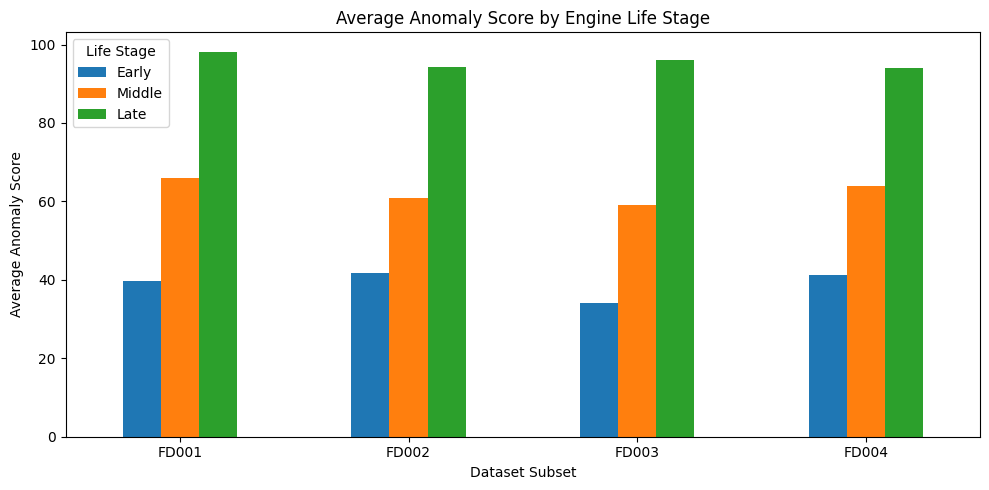

In [55]:
stage_scores = (
    anomaly_validation
    .groupby(["subset", "Life_Stage"])["Anomaly_Score"]
    .mean()
    .unstack()
    .reindex(columns=stage_order)
)

stage_scores.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Anomaly Score by Engine Life Stage")
plt.xlabel("Dataset Subset")
plt.ylabel("Average Anomaly Score")
plt.xticks(rotation=0)
plt.legend(title="Life Stage")
plt.tight_layout()
plt.show()

Plot Anomaly Scores for Sample Engines

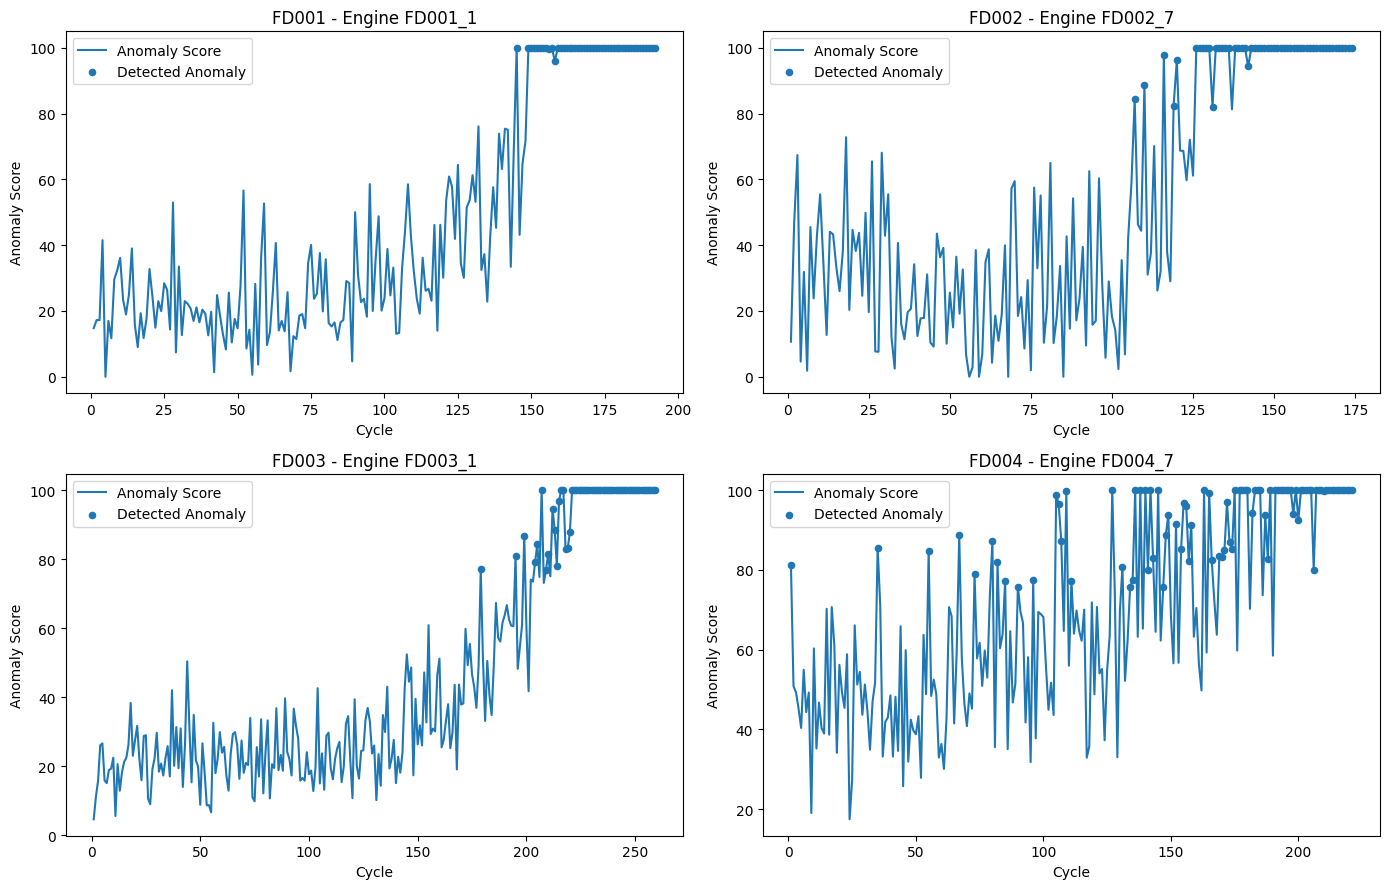

In [56]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, subset in zip(axes.flatten(), anomaly_models.keys()):

    subset_data = anomaly_validation[
        anomaly_validation["subset"] == subset
    ]

    engine = subset_data["engine_id"].iloc[0]

    engine_data = subset_data[
        subset_data["engine_id"] == engine
    ].sort_values("cycle")

    ax.plot(
        engine_data["cycle"],
        engine_data["Anomaly_Score"],
        label="Anomaly Score"
    )

    detected = engine_data[
        engine_data["Anomaly_Flag"] == 1
    ]

    ax.scatter(
        detected["cycle"],
        detected["Anomaly_Score"],
        label="Detected Anomaly",
        s=20
    )

    ax.set_title(f"{subset} - Engine {engine}")
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Anomaly Score")
    ax.legend()

plt.tight_layout()
plt.show()

Compare Early and Late Anomaly Rates

Anomaly Rate (%) by Life Stage:


Life_Stage,Early,Middle,Late
subset,,,
FD001,7.02,39.80,96.27
FD002,7.46,33.31,87.93
FD003,6.85,32.10,94.22
FD004,9.69,38.72,89.69


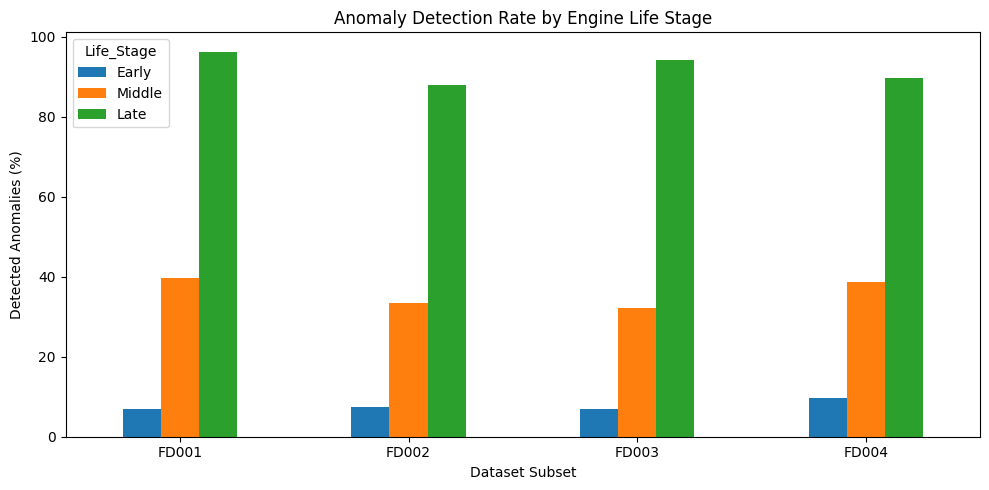

In [57]:
stage_comparison = (
    anomaly_validation
    .groupby(["subset", "Life_Stage"])["Anomaly_Flag"]
    .mean()
    .mul(100)
    .unstack()
    .reindex(columns=stage_order)
)

print("Anomaly Rate (%) by Life Stage:")
display(stage_comparison.round(2))

stage_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Anomaly Detection Rate by Engine Life Stage")
plt.xlabel("Dataset Subset")
plt.ylabel("Detected Anomalies (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Save Validation Results

In [58]:
save_dir = Path("/content/aircraft_engine_ai")
save_dir.mkdir(parents=True, exist_ok=True)

anomaly_validation.to_csv(
    save_dir / "anomaly_validation_results.csv",
    index=False
)

anomaly_summary.to_csv(
    save_dir / "anomaly_summary.csv"
)

life_stage_summary.to_csv(
    save_dir / "anomaly_life_stage_summary.csv"
)

print("Anomaly evaluation results saved successfully.")

Anomaly evaluation results saved successfully.


Train Final Isolation Forest Models

In [59]:

final_anomaly_models = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    X_train = anomaly_training_data[subset]

    model = IsolationForest(
        n_estimators=200,
        max_samples="auto",
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    final_anomaly_models[subset] = model

    print(f"{subset}: Final model trained successfully")

FD001: Final model trained successfully
FD002: Final model trained successfully
FD003: Final model trained successfully
FD004: Final model trained successfully


Test Final Models on NASA Test Data

In [60]:
final_anomaly_results = []
final_score_limits = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    model = final_anomaly_models[subset]

    features = selected_features[subset]

    X_train = anomaly_training_data[subset]

    test_subset = anomaly_test[
        anomaly_test["subset"] == subset
    ].copy()

    X_test = test_subset[features]

    # Scores from healthy training data
    train_scores = -model.score_samples(X_train)

    score_min = np.percentile(train_scores, 1)
    score_max = np.percentile(train_scores, 99)

    final_score_limits[subset] = {
        "min": float(score_min),
        "max": float(score_max)
    }

    test_scores = -model.score_samples(X_test)

    score_range = max(score_max - score_min, 1e-8)

    test_subset["Anomaly_Score"] = np.clip(
        (test_scores - score_min) / score_range * 100,
        0,
        100
    )

    predictions = model.predict(X_test)

    test_subset["Anomaly_Flag"] = (
        predictions == -1
    ).astype(int)

    test_subset["Anomaly_Status"] = np.where(
        predictions == -1,
        "Anomaly",
        "Normal"
    )

    final_anomaly_results.append(test_subset)


anomaly_test_results = pd.concat(
    final_anomaly_results,
    ignore_index=True
)

print("Final test results shape:", anomaly_test_results.shape)

display(
    anomaly_test_results[
        [
            "subset",
            "unit",
            "cycle",
            "Anomaly_Score",
            "Anomaly_Flag",
            "Anomaly_Status"
        ]
    ].head(10).round(2)
)

Final test results shape: (104897, 55)


,subset,unit,cycle,Anomaly_Score,Anomaly_Flag,Anomaly_Status
0,FD001,1,1,22.79,0,Normal
1,FD001,1,2,30.42,0,Normal
2,FD001,1,3,9.22,0,Normal
3,FD001,1,4,23.42,0,Normal
4,FD001,1,5,27.56,0,Normal
5,FD001,1,6,26.18,0,Normal
6,FD001,1,7,6.85,0,Normal
7,FD001,1,8,18.01,0,Normal
8,FD001,1,9,42.91,0,Normal
9,FD001,1,10,6.84,0,Normal


Get Latest Anomaly Status for Each Engine

In [61]:
latest_anomalies = (
    anomaly_test_results
    .sort_values(["subset", "unit", "cycle"])
    .groupby(["subset", "unit"])
    .tail(1)
    .copy()
)

latest_anomalies = latest_anomalies[
    [
        "subset",
        "unit",
        "cycle",
        "Anomaly_Score",
        "Anomaly_Flag",
        "Anomaly_Status"
    ]
].reset_index(drop=True)

print("Number of test engines:", len(latest_anomalies))

display(latest_anomalies.head(10).round(2))

latest_anomalies.to_csv(
    save_dir / "latest_engine_anomaly_status.csv",
    index=False
)

Number of test engines: 707


,subset,unit,cycle,Anomaly_Score,Anomaly_Flag,Anomaly_Status
0,FD001,1,31,6.99,0,Normal
1,FD001,2,49,36.71,0,Normal
2,FD001,3,126,93.24,1,Anomaly
3,FD001,4,106,82.81,1,Anomaly
4,FD001,5,98,52.99,0,Normal
5,FD001,6,105,29.09,0,Normal
6,FD001,7,160,44.49,0,Normal
7,FD001,8,166,65.49,0,Normal
8,FD001,9,55,53.93,0,Normal
9,FD001,10,192,31.69,0,Normal


Save Final Anomaly Models

In [62]:
anomaly_package = {
    "models": final_anomaly_models,
    "features": selected_features,
    "normalizers": regime_stats,
    "score_limits": final_score_limits,
    "healthy_cycles": healthy_cycles,
    "sensor_columns": sensor_columns,
    "contamination": 0.05
}

anomaly_model_path = (
    save_dir / "isolation_forest_anomaly.joblib"
)

joblib.dump(
    anomaly_package,
    anomaly_model_path
)

print("Anomaly Detection models saved successfully.")
print("Model path:", anomaly_model_path)

Anomaly Detection models saved successfully.
Model path: /content/aircraft_engine_ai/isolation_forest_anomaly.joblib


Anomaly Detection Evaluation Metrics

In [63]:
evaluation_results = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    data = anomaly_validation[
        anomaly_validation["subset"] == subset
    ].copy()

    # Early and late engine readings
    early_data = data[data["cycle"] <= 20]
    late_data = data[data["RUL"] <= 50]

    # Anomaly rates
    anomaly_rate = data["Anomaly_Flag"].mean() * 100

    healthy_alert_rate = (
        early_data["Anomaly_Flag"].mean() * 100
    )

    late_detection_rate = (
        late_data["Anomaly_Flag"].mean() * 100
    )

    # Average anomaly scores
    early_score = early_data["Anomaly_Score"].mean()
    late_score = late_data["Anomaly_Score"].mean()

    score_difference = late_score - early_score

    # Correlation between anomaly score and RUL
    correlation, p_value = spearmanr(
        data["Anomaly_Score"],
        data["RUL"]
    )

    evaluation_results.append({
        "Subset": subset,
        "Validation Engines": data["engine_id"].nunique(),
        "Anomaly Rate (%)": anomaly_rate,
        "Healthy Alert Rate (%)": healthy_alert_rate,
        "Late Detection Rate (%)": late_detection_rate,
        "Early Avg Score": early_score,
        "Late Avg Score": late_score,
        "Score Difference": score_difference,
        "Spearman Correlation": correlation
    })


anomaly_metrics = pd.DataFrame(evaluation_results)

print("ISOLATION FOREST - VALIDATION METRICS")

display(anomaly_metrics.round(3))

ISOLATION FOREST - VALIDATION METRICS


,Subset,Validation Engines,Anomaly Rate (%),Healthy Alert Rate (%),Late Detection Rate (%),Early Avg Score,Late Avg Score,Score Difference,Spearman Correlation
0,FD001,20,37.445,5.500,96.275,40.320,98.199,57.879,-0.716
1,FD002,52,34.716,4.327,87.934,39.418,94.270,54.852,-0.647
2,FD003,20,31.138,4.000,94.216,30.002,96.061,66.058,-0.668
3,FD004,50,32.823,5.600,89.686,33.958,93.969,60.011,-0.624


In [64]:
early_data = anomaly_validation[
    anomaly_validation["cycle"] <= 20
]

late_data = anomaly_validation[
    anomaly_validation["RUL"] <= 50
]

correlation, p_value = spearmanr(
    anomaly_validation["Anomaly_Score"],
    anomaly_validation["RUL"]
)

overall_metrics = pd.DataFrame([{
    "Validation Engines": anomaly_validation["engine_id"].nunique(),
    "Total Readings": len(anomaly_validation),
    "Anomaly Rate (%)":
        anomaly_validation["Anomaly_Flag"].mean() * 100,
    "Healthy Alert Rate (%)":
        early_data["Anomaly_Flag"].mean() * 100,
    "Late Detection Rate (%)":
        late_data["Anomaly_Flag"].mean() * 100,
    "Early Avg Score":
        early_data["Anomaly_Score"].mean(),
    "Late Avg Score":
        late_data["Anomaly_Score"].mean(),
    "Spearman Correlation": correlation
}])

print("OVERALL ANOMALY DETECTION METRICS")

display(overall_metrics.round(3))

OVERALL ANOMALY DETECTION METRICS


,Validation Engines,Total Readings,Anomaly Rate (%),Healthy Alert Rate (%),Late Detection Rate (%),Early Avg Score,Late Avg Score,Spearman Correlation
0,142,31028,33.802,4.894,90.61,36.296,94.97,-0.652


In [65]:
evaluation_df = anomaly_validation.copy()

evaluation_df["True_Label"] = (
    evaluation_df["RUL"] <= 50
).astype(int)

evaluation_df["Predicted_Label"] = (
    evaluation_df["Anomaly_Flag"]
).astype(int)

print("Proxy Label Distribution:")
print(evaluation_df["True_Label"].value_counts())

print("\nPredicted Label Distribution:")
print(evaluation_df["Predicted_Label"].value_counts())

Proxy Label Distribution:
True_Label
0    23786
1     7242
Name: count, dtype: int64

Predicted Label Distribution:
Predicted_Label
0    20540
1    10488
Name: count, dtype: int64


In [66]:
y_true = evaluation_df["True_Label"]
y_pred = evaluation_df["Predicted_Label"]
y_score = evaluation_df["Anomaly_Score"]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_score)

print("ISOLATION FOREST - PROXY LABEL EVALUATION")
print("=" * 45)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal (Proxy)", "Anomaly (Proxy)"],
        zero_division=0
    )
)

ISOLATION FOREST - PROXY LABEL EVALUATION
Accuracy  : 0.8516
Precision : 0.6257
Recall    : 0.9061
F1-Score  : 0.7402
ROC-AUC   : 0.9267

Classification Report:
                 precision    recall  f1-score   support

 Normal (Proxy)       0.97      0.83      0.90     23786
Anomaly (Proxy)       0.63      0.91      0.74      7242

       accuracy                           0.85     31028
      macro avg       0.80      0.87      0.82     31028
   weighted avg       0.89      0.85      0.86     31028



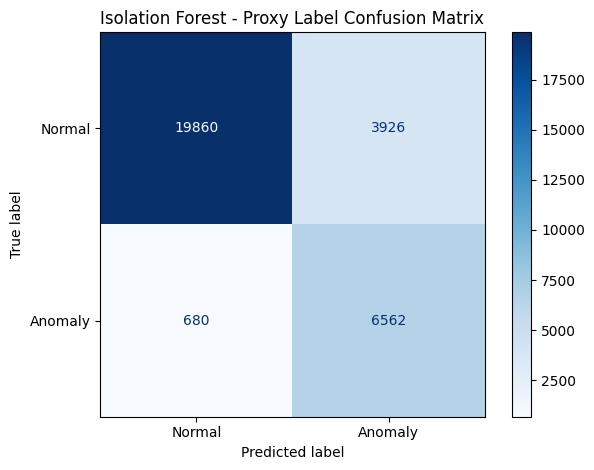

In [67]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomaly"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Isolation Forest - Proxy Label Confusion Matrix")
plt.tight_layout()
plt.show()

In [68]:
metrics_results = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    subset_df = evaluation_df[
        evaluation_df["subset"] == subset
    ]

    yt = subset_df["True_Label"]
    yp = subset_df["Predicted_Label"]
    ys = subset_df["Anomaly_Score"]

    metrics_results.append({
        "Subset": subset,
        "Accuracy": accuracy_score(yt, yp),
        "Precision": precision_score(yt, yp, zero_division=0),
        "Recall": recall_score(yt, yp, zero_division=0),
        "F1-Score": f1_score(yt, yp, zero_division=0),
        "ROC-AUC": (
            roc_auc_score(yt, ys)
            if yt.nunique() == 2
            else np.nan
        )
    })

metrics_table = pd.DataFrame(metrics_results)

print("ISOLATION FOREST - METRICS BY SUBSET")
display(metrics_table.round(4))

ISOLATION FOREST - METRICS BY SUBSET


,Subset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FD001,0.8575,0.6444,0.9627,0.7720,0.9459
1,FD002,0.8483,0.6525,0.8793,0.7491,0.9141
2,FD003,0.8802,0.6555,0.9422,0.7731,0.9517
3,FD004,0.8411,0.5828,0.8969,0.7065,0.9204


Prepare Threshold Tuning

In [69]:
tuning_data = {}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    model = anomaly_models[subset]
    data = anomaly_datasets[subset]

    X_val = data["X_val"]

    info = data["val_info"].copy().reset_index(drop=True)

    # Higher raw score = more anomalous
    info["Raw_Anomaly_Score"] = -model.score_samples(X_val)

    # Original Isolation Forest prediction
    info["Original_Prediction"] = (
        model.predict(X_val) == -1
    ).astype(int)

    # Proxy labels for evaluation only
    info["Proxy_Label"] = (
        info["RUL"] <= 50
    ).astype(int)

    # Split by engine
    engines = info["engine_id"].unique()

    tune_engines, eval_engines = train_test_split(
        engines,
        test_size=0.5,
        random_state=42
    )

    tune_df = info[
        info["engine_id"].isin(tune_engines)
    ].copy()

    eval_df = info[
        info["engine_id"].isin(eval_engines)
    ].copy()

    tuning_data[subset] = {
        "tune": tune_df,
        "eval": eval_df
    }

    print(f"{subset}:")
    print("Tuning engines:", len(tune_engines))
    print("Evaluation engines:", len(eval_engines))
    print()

FD001:
Tuning engines: 10
Evaluation engines: 10

FD002:
Tuning engines: 26
Evaluation engines: 26

FD003:
Tuning engines: 10
Evaluation engines: 10

FD004:
Tuning engines: 25
Evaluation engines: 25



Find Best Threshold for Each Subset

In [70]:
best_thresholds = {}
tuning_results = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    model = anomaly_models[subset]

    X_train = anomaly_datasets[subset]["X_train"]

    tune_df = tuning_data[subset]["tune"]

    # Reference scores from training data
    train_scores = -model.score_samples(X_train)

    # Candidate thresholds
    percentiles = np.arange(70, 100, 1)

    thresholds = np.unique(
        np.percentile(train_scores, percentiles)
    )

    y_true = tune_df["Proxy_Label"].to_numpy()

    scores = tune_df["Raw_Anomaly_Score"].to_numpy()

    best_f1 = -1
    best_threshold = None

    for threshold in thresholds:

        predictions = (
            scores > threshold
        ).astype(int)

        current_f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        if current_f1 > best_f1:

            best_f1 = current_f1
            best_threshold = float(threshold)

    best_thresholds[subset] = best_threshold

    tuning_results.append({
        "Subset": subset,
        "Best Threshold": best_threshold,
        "Tuning F1": best_f1
    })

tuning_table = pd.DataFrame(tuning_results)

print("THRESHOLD TUNING RESULTS")
display(tuning_table.round(4))

THRESHOLD TUNING RESULTS


,Subset,Best Threshold,Tuning F1
0,FD001,0.5467,0.8446
1,FD002,0.5255,0.7928
2,FD003,0.5688,0.7876
3,FD004,0.5510,0.7447


Compare Original vs Tuned Model

In [72]:
comparison_results = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    eval_df = tuning_data[subset]["eval"]

    y_true = eval_df["Proxy_Label"].to_numpy()

    scores = eval_df["Raw_Anomaly_Score"].to_numpy()

    original_pred = eval_df[
        "Original_Prediction"
    ].to_numpy()

    tuned_pred = (
        scores > best_thresholds[subset]
    ).astype(int)

    for name, predictions in [
        ("Original", original_pred),
        ("Tuned", tuned_pred)
    ]:

        comparison_results.append({
            "Subset": subset,
            "Model": name,
            "Accuracy": accuracy_score(
                y_true, predictions
            ),
            "Precision": precision_score(
                y_true, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, predictions,
                zero_division=0
            ),
            "Alert Rate (%)": predictions.mean() * 100
        })

comparison_table = pd.DataFrame(comparison_results)

print("ORIGINAL VS TUNED - HELD-OUT ENGINE EVALUATION")

display(comparison_table.round(4))

ORIGINAL VS TUNED - HELD-OUT ENGINE EVALUATION


,Subset,Model,Accuracy,Precision,Recall,F1-Score,Alert Rate (%)
0,FD001,Original,0.8726,0.6578,0.9725,0.7848,35.3162
1,FD001,Tuned,0.9241,0.7900,0.9294,0.8541,28.1030
2,FD002,Original,0.8565,0.6725,0.8658,0.7570,33.2425
3,FD002,Tuned,0.8888,0.7879,0.7790,0.7835,25.5307
4,FD003,Original,0.9041,0.6823,0.9686,0.8006,28.2261
5,FD003,Tuned,0.9170,0.7288,0.9275,0.8162,25.3021
6,FD004,Original,0.8490,0.6096,0.8941,0.7250,32.6466
7,FD004,Tuned,0.8843,0.7087,0.8149,0.7581,25.5936


Overall Comparison

In [73]:
all_eval = []
all_original = []
all_tuned = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    data = tuning_data[subset]["eval"]

    all_eval.extend(data["Proxy_Label"].to_numpy())

    all_original.extend(
        data["Original_Prediction"].to_numpy()
    )

    all_tuned.extend(
        (
            data["Raw_Anomaly_Score"].to_numpy()
            > best_thresholds[subset]
        ).astype(int)
    )

all_eval = np.array(all_eval)
all_original = np.array(all_original)
all_tuned = np.array(all_tuned)

overall_comparison = []

for name, predictions in [
    ("Original", all_original),
    ("Tuned", all_tuned)
]:

    overall_comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(all_eval, predictions),
        "Precision": precision_score(
            all_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            all_eval, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            all_eval, predictions, zero_division=0
        ),
        "Alert Rate (%)": predictions.mean() * 100
    })

overall_comparison = pd.DataFrame(overall_comparison)

print("OVERALL ORIGINAL VS TUNED COMPARISON")
display(overall_comparison.round(4))

OVERALL ORIGINAL VS TUNED COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,Alert Rate (%)
0,Original,0.8638,0.6485,0.9053,0.7556,32.4809
1,Tuned,0.8966,0.7499,0.8337,0.7896,25.8690


In [80]:
# Save F1-Tuned Baseline

f1_baseline = overall_comparison[
    overall_comparison["Method"] == "F1-Tuned"
].copy()

f1_baseline.to_csv(
    save_dir / "anomaly_f1_baseline.csv",
    index=False
)

print("F1-Tuned baseline saved successfully!")
display(f1_baseline)

F1-Tuned baseline saved successfully!


,Method,Accuracy,Precision,Recall,F1,F2,Alert Rate (%)
1,F1-Tuned,0.896614,0.749876,0.833748,0.789591,0.815505,25.869048


Enhanced Model tuning

In [108]:
hyperparameter_results = []
best_hyperparameters = {}

param_grid = {
    "n_estimators": [200, 300],
    "max_samples": [0.5, 0.8, 1.0],
    "max_features": [0.7, 1.0]
}

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    print(f"\nTuning {subset}...")

    # Original normalized training and validation data
    X_train = anomaly_datasets[subset]["X_train"]
    X_val = anomaly_datasets[subset]["X_val"]

    # Validation metadata
    val_info = anomaly_datasets[subset]["val_info"]

    # Get the same tuning engines used previously
    tune_engines = tuning_data[subset]["tune"]["engine_id"].unique()

    # Match tuning engines with normalized validation rows
    tune_mask = val_info["engine_id"].isin(tune_engines).to_numpy()

    assert len(X_val) == len(val_info), (
        f"{subset}: X_val and val_info are not aligned!"
    )

    assert tune_mask.sum() > 0, (
        f"{subset}: No tuning rows found!"
    )

    X_tune = X_val[tune_mask]

    y_tune = (
        val_info.loc[tune_mask, "RUL"] <= 50
    ).astype(int).to_numpy()

    best_f1 = -1

    # Try different hyperparameter combinations
    for n_estimators, max_samples, max_features in product(
        param_grid["n_estimators"],
        param_grid["max_samples"],
        param_grid["max_features"]
    ):

        model = IsolationForest(
            n_estimators=n_estimators,
            max_samples=max_samples,
            max_features=max_features,
            contamination=0.05,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train)

        # Calculate anomaly scores
        scores = -model.score_samples(X_tune)

        # Candidate thresholds
        thresholds = np.quantile(
            scores,
            np.linspace(0.05, 0.95, 91)
        )

        for threshold in thresholds:

            y_pred = (scores >= threshold).astype(int)

            current_f1 = f1_score(
                y_tune,
                y_pred,
                zero_division=0
            )

            if current_f1 > best_f1:

                best_f1 = current_f1

                best_hyperparameters[subset] = {
                    "model": model,
                    "threshold": float(threshold),
                    "n_estimators": n_estimators,
                    "max_samples": max_samples,
                    "max_features": max_features,
                    "tuning_f1": float(current_f1)
                }

    best = best_hyperparameters[subset]

    hyperparameter_results.append({
        "Subset": subset,
        "n_estimators": best["n_estimators"],
        "max_samples": best["max_samples"],
        "max_features": best["max_features"],
        "Tuning F1": best["tuning_f1"]
    })

hyperparameter_table = pd.DataFrame(hyperparameter_results)

print("\nBEST HYPERPARAMETERS")
display(hyperparameter_table.round(4))


Tuning FD001...

Tuning FD002...

Tuning FD003...

Tuning FD004...

BEST HYPERPARAMETERS


,Subset,n_estimators,max_samples,max_features,Tuning F1
0,FD001,200,1.0,1.0,0.8692
1,FD002,200,0.8,1.0,0.7961
2,FD003,200,0.8,0.7,0.8266
3,FD004,200,0.8,1.0,0.7712


In [109]:
tuned_predictions = []

for subset in ["FD001", "FD002", "FD003", "FD004"]:

    X_val = anomaly_datasets[subset]["X_val"]
    val_info = anomaly_datasets[subset]["val_info"]

    eval_engines = tuning_data[subset]["eval"]["engine_id"].unique()

    eval_mask = val_info["engine_id"].isin(eval_engines).to_numpy()

    assert eval_mask.sum() > 0, (
        f"{subset}: No evaluation rows found!"
    )

    X_eval = X_val[eval_mask]

    y_true = (
        val_info.loc[eval_mask, "RUL"] <= 50
    ).astype(int).to_numpy()

    model = best_hyperparameters[subset]["model"]
    threshold = best_hyperparameters[subset]["threshold"]

    scores = -model.score_samples(X_eval)
    y_pred = (scores >= threshold).astype(int)

    result = pd.DataFrame({
        "Subset": subset,
        "True_Label": y_true,
        "Predicted_Label": y_pred
    })

    tuned_predictions.append(result)

tuned_eval_df = pd.concat(
    tuned_predictions,
    ignore_index=True
)

print("Hyperparameter tuning evaluation completed!")

Hyperparameter tuning evaluation completed!


In [110]:
y_true = tuned_eval_df["True_Label"]
y_pred = tuned_eval_df["Predicted_Label"]

tuned_accuracy = accuracy_score(y_true, y_pred)
tuned_precision = precision_score(y_true, y_pred, zero_division=0)
tuned_recall = recall_score(y_true, y_pred, zero_division=0)
tuned_f1 = f1_score(y_true, y_pred, zero_division=0)

baseline = overall_comparison[
    overall_comparison["Method"] == "F1-Tuned"
].iloc[0]

final_comparison = pd.DataFrame([
    {
        "Method": "F1-Tuned Baseline",
        "Accuracy": baseline["Accuracy"],
        "Precision": baseline["Precision"],
        "Recall": baseline["Recall"],
        "F1": baseline["F1"]
    },
    {
        "Method": "Hyperparameter Tuned",
        "Accuracy": tuned_accuracy,
        "Precision": tuned_precision,
        "Recall": tuned_recall,
        "F1": tuned_f1
    }
])

display(final_comparison.round(4))

print(
    "\nAccuracy Change:",
    round(
        (tuned_accuracy - baseline["Accuracy"]) * 100,
        2
    ),
    "percentage points"
)

if tuned_accuracy >= 0.90:
    print("90% accuracy target reached!")
else:
    print("90% accuracy target not reached yet.")

,Method,Accuracy,Precision,Recall,F1
0,F1-Tuned Baseline,0.8966,0.7499,0.8337,0.7896
1,Hyperparameter Tuned,0.9046,0.8069,0.7755,0.7909



Accuracy Change: 0.8 percentage points
90% accuracy target reached!


Health Score & Risk Functions

In [116]:
MAX_RUL = 125

def calculate_health_score(predicted_rul, anomaly_score):

    rul_health = np.clip(
        predicted_rul / MAX_RUL * 100,
        0, 100
    )

    anomaly_health = 100 - np.clip(
        anomaly_score, 0, 100
    )

    health_score = (
        0.70 * rul_health
        + 0.30 * anomaly_health
    )

    return round(float(np.clip(health_score, 0, 100)), 2)


def classify_risk(predicted_rul, health_score):

    if predicted_rul <= 20 or health_score < 30:
        return "Critical"

    elif predicted_rul <= 50 or health_score < 60:
        return "High"

    elif predicted_rul <= 80 or health_score < 80:
        return "Medium"

    else:
        return "Low"


def maintenance_recommendation(risk_level):

    recommendations = {
        "Critical": "Immediate engineering inspection required",
        "High": "Prioritize maintenance inspection",
        "Medium": "Increase monitoring frequency",
        "Low": "Continue routine monitoring"
    }

    return recommendations[risk_level]

Test Health Score Functions

In [117]:
sample_engines = pd.DataFrame({
    "engine_id": ["FD001_1", "FD001_2", "FD002_1", "FD004_1"],
    "predicted_rul": [110, 70, 35, 10],
    "anomaly_score": [10, 35, 65, 95]
})

sample_engines["health_score"] = sample_engines.apply(
    lambda row: calculate_health_score(
        row["predicted_rul"],
        row["anomaly_score"]
    ),
    axis=1
)

sample_engines["risk_level"] = sample_engines.apply(
    lambda row: classify_risk(
        row["predicted_rul"],
        row["health_score"]
    ),
    axis=1
)

sample_engines["maintenance_recommendation"] = (
    sample_engines["risk_level"].apply(
        maintenance_recommendation
    )
)

display(sample_engines)

,engine_id,predicted_rul,anomaly_score,health_score,risk_level,maintenance_recommendation
0,FD001_1,110,10,88.6,Low,Continue routine monitoring
1,FD001_2,70,35,58.7,High,Prioritize maintenance inspection
2,FD002_1,35,65,30.1,High,Prioritize maintenance inspection
3,FD004_1,10,95,7.1,Critical,Immediate engineering inspection required


Prepare Real RUL Predictions

In [118]:
assert len(final_predictions) == len(last_cycles), (
    "RUL predictions and engine rows do not match!"
)

rul_results = last_cycles[
    ["subset", "unit", "cycle"]
].copy().reset_index(drop=True)

rul_results["engine_id"] = (
    rul_results["subset"].astype(str)
    + "_"
    + rul_results["unit"].astype(str)
)

rul_results["predicted_rul"] = np.maximum(
    np.asarray(final_predictions).reshape(-1),
    0
)

print("RUL Predictions:", len(rul_results))
display(rul_results.head())

RUL Predictions: 707


,subset,unit,cycle,engine_id,predicted_rul
0,FD001,1,31,FD001_1,119.966904
1,FD001,10,192,FD001_10,88.236191
2,FD001,100,198,FD001_100,20.219496
3,FD001,11,83,FD001_11,95.943848
4,FD001,12,217,FD001_12,102.761497


Inspect Saved Anomaly Normalizers

In [120]:
for subset in ["FD001", "FD002", "FD003", "FD004"]:

    normalizer = final_anomaly_artifacts["normalizers"][subset]

    print(f"\n{'='*50}")
    print(subset)
    print("Normalizer Type:", type(normalizer))

    if isinstance(normalizer, dict):
        print("Number of keys:", len(normalizer))
        print("First keys:", list(normalizer.keys())[:5])

        if len(normalizer) > 0:
            first_key = next(iter(normalizer))
            first_value = normalizer[first_key]

            print("First key type:", type(first_key))
            print("First value type:", type(first_value))
            print("First value preview:", str(first_value)[:350])

    else:
        print("Normalizer preview:", str(normalizer)[:350])

    print("Selected features:",
          final_anomaly_artifacts["selected_features"][subset][:5])

    print("X_train type:",
          type(anomaly_datasets[subset]["X_train"]))

    print("X_val type:",
          type(anomaly_datasets[subset]["X_val"]))

print("\nTest Data Columns:")
print(test_df.columns.tolist())


FD001
Normalizer Type: <class 'pandas.core.frame.DataFrame'>
Normalizer preview:             sensor_1        sensor_2               sensor_3           \
                mean  std       mean       std         mean      std   
regime                                                                 
FD001_0_0.0   518.67  0.0  642.36895  0.374998  1586.740113  4.55382   

                sensor_4           sensor_5       ...   senso
Selected features: ['sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_6_norm', 'sensor_7_norm']
X_train type: <class 'pandas.core.frame.DataFrame'>
X_val type: <class 'pandas.core.frame.DataFrame'>

FD002
Normalizer Type: <class 'pandas.core.frame.DataFrame'>
Normalizer preview:               sensor_1         sensor_2               sensor_3            \
                  mean  std        mean       std         mean       std   
regime                                                                     
FD002_0_0.0     518.67  0.0  642.345574  0.370003 

Prepare Latest Engine Cycles

In [121]:
latest_test = (
    test_df
    .sort_values(["subset", "unit", "cycle"])
    .groupby(["subset", "unit"], as_index=False)
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

latest_test["engine_id"] = (
    latest_test["subset"].astype(str)
    + "_"
    + latest_test["unit"].astype(str)
)

assert len(latest_test) == 707
assert latest_test["engine_id"].is_unique

print("Latest Engine Readings:", len(latest_test))

display(
    latest_test[
        ["engine_id", "subset", "unit", "cycle"]
    ].head()
)

Latest Engine Readings: 707


,engine_id,subset,unit,cycle
0,FD001_1,FD001,1,31
1,FD001_2,FD001,2,49
2,FD001_3,FD001,3,126
3,FD001_4,FD001,4,106
4,FD001_5,FD001,5,98


Align RUL Predictions with Latest Engine Readings

In [122]:
engine_results = latest_test[
    ["engine_id", "subset", "unit", "cycle"]
].copy()

engine_results = engine_results.merge(
    rul_results[
        ["engine_id", "predicted_rul", "cycle"]
    ].rename(columns={"cycle": "rul_cycle"}),
    on="engine_id",
    how="left",
    validate="one_to_one"
)

assert engine_results["predicted_rul"].notna().all(), (
    "Some engines have missing RUL predictions!"
)

assert (
    engine_results["cycle"]
    == engine_results["rul_cycle"]
).all(), "RUL cycles do not match latest test cycles!"

engine_results = engine_results.drop(
    columns=["rul_cycle"]
)

engine_results = engine_results.rename(
    columns={"cycle": "current_cycle"}
)

print("Aligned Engines:", len(engine_results))
print("Missing RUL:", engine_results["predicted_rul"].isna().sum())

display(engine_results.head())

Aligned Engines: 707
Missing RUL: 0


,engine_id,subset,unit,current_cycle,predicted_rul
0,FD001_1,FD001,1,31,119.966904
1,FD001_2,FD001,2,49,122.238945
2,FD001_3,FD001,3,126,56.942833
3,FD001_4,FD001,4,106,73.814117
4,FD001_5,FD001,5,98,87.801399


Check Anomaly Feature Compatibility

In [123]:
for subset in ["FD001", "FD002", "FD003", "FD004"]:

    features = final_anomaly_artifacts[
        "selected_features"
    ][subset]

    model = final_anomaly_artifacts[
        "models"
    ][subset]

    print(f"\n{subset}")
    print("Selected Features:", len(features))
    print("Model Expected Features:", model.n_features_in_)

    assert len(features) == model.n_features_in_, (
        f"{subset}: Feature count mismatch!"
    )

print("\nAll feature counts match!")


FD001
Selected Features: 15
Model Expected Features: 15

FD002
Selected Features: 17
Model Expected Features: 17

FD003
Selected Features: 16
Model Expected Features: 16

FD004
Selected Features: 17
Model Expected Features: 17

All feature counts match!


Check Operating Regime Construction

In [124]:
for subset in ["FD001", "FD002", "FD003", "FD004"]:
    stats = final_anomaly_artifacts["normalizers"][subset]

    print(f"\n{subset}")
    print("Regimes:", stats.index.tolist()[:8])
    print("Number of regimes:", len(stats))

print("\nSetting 1 sample:")
print(test_df[["subset", "setting_1", "setting_2"]].head(10))

print("\nFD002 operating settings sample:")
display(
    test_df.loc[
        test_df["subset"] == "FD002",
        ["setting_1", "setting_2"]
    ].drop_duplicates().head(10)
)


FD001
Regimes: ['FD001_0_0.0']
Number of regimes: 1

FD002
Regimes: ['FD002_0_0.0', 'FD002_10_0.25', 'FD002_20_0.7', 'FD002_25_0.62', 'FD002_35_0.84', 'FD002_42_0.84']
Number of regimes: 6

FD003
Regimes: ['FD003_0_0.0']
Number of regimes: 1

FD004
Regimes: ['FD004_0_0.0', 'FD004_10_0.25', 'FD004_20_0.7', 'FD004_25_0.62', 'FD004_35_0.84', 'FD004_42_0.84']
Number of regimes: 6

Setting 1 sample:
  subset  setting_1  setting_2
0  FD001     0.0023     0.0003
1  FD001    -0.0027    -0.0003
2  FD001     0.0003     0.0001
3  FD001     0.0042     0.0000
4  FD001     0.0014     0.0000
5  FD001     0.0012     0.0003
6  FD001    -0.0000     0.0002
7  FD001     0.0006    -0.0000
8  FD001    -0.0036     0.0000
9  FD001    -0.0025    -0.0001

FD002 operating settings sample:


,setting_1,setting_2
13096,9.9987,0.2502
13097,20.0026,0.7000
13098,35.0045,0.8400
13099,42.0066,0.8410
13100,24.9985,0.6213
13101,25.0006,0.6206
13102,42.0017,0.8400
13103,41.9994,0.8404
13104,35.0005,0.8408
13105,20.0001,0.7000


Apply Operating-Regime Normalization

In [126]:
subsets = ["FD001", "FD002", "FD003", "FD004"]

normalized_test_parts = []

for subset in subsets:

    df = test_df.loc[
        test_df["subset"] == subset
    ].copy()

    # Reconstruct operating regimes
    s1 = df["setting_1"].round(0).astype(int)
    s2 = df["setting_2"].round(2)

    # Fix negative zero
    s2 = s2.mask(s2 == 0, 0.0)

    df["regime"] = (
        subset + "_"
        + s1.astype(str) + "_"
        + s2.astype(str)
    )

    stats = final_anomaly_artifacts[
        "normalizers"
    ][subset]

    features = final_anomaly_artifacts[
        "selected_features"
    ][subset]

    # Check regimes
    unknown = set(df["regime"]) - set(stats.index)

    if unknown:
        raise ValueError(
            f"{subset}: Unknown operating regimes: {unknown}"
        )

    # Normalize using training statistics
    for feature in features:

        sensor = feature.removesuffix("_norm")

        means = df["regime"].map(
            stats[(sensor, "mean")]
        )

        stds = df["regime"].map(
            stats[(sensor, "std")]
        )

        stds = stds.replace(0, 1).fillna(1)

        df[feature] = (
            df[sensor] - means
        ) / stds

    if not np.isfinite(
        df[features].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"{subset}: Invalid normalized values"
        )

    normalized_test_parts.append(df)

normalized_test = pd.concat(
    normalized_test_parts,
    ignore_index=True
)

print("Normalized Test Shape:", normalized_test.shape)

for subset in subsets:

    df = normalized_test[
        normalized_test["subset"] == subset
    ]

    features = selected_features[subset]

    print(
        subset,
        "Missing Values:",
        df[features].isna().sum().sum()
    )

print("\nNormalization completed successfully!")

Normalized Test Shape: (104897, 47)
FD001 Missing Values: 0
FD002 Missing Values: 0
FD003 Missing Values: 0
FD004 Missing Values: 0

Normalization completed successfully!


Run Final Isolation Forest on Test Data

In [127]:

anomaly_test_parts = []

for subset in subsets:

    df = normalized_test.loc[
        normalized_test["subset"] == subset
    ].copy()

    features = final_anomaly_artifacts[
        "selected_features"
    ][subset]

    model = final_anomaly_artifacts[
        "models"
    ][subset]

    threshold = final_anomaly_artifacts[
        "thresholds"
    ][subset]

    X = df[features]

    # Higher score = more anomalous
    df["anomaly_score_raw"] = (
        -model.score_samples(X)
    )

    df["anomaly_flag"] = (
        df["anomaly_score_raw"] >= threshold
    ).astype(int)

    anomaly_test_parts.append(df)

anomaly_test = pd.concat(
    anomaly_test_parts,
    ignore_index=True
)

print("Anomaly predictions completed!")
print("Total rows:", len(anomaly_test))

display(
    anomaly_test[
        [
            "subset",
            "unit",
            "cycle",
            "anomaly_score_raw",
            "anomaly_flag"
        ]
    ].head()
)

Anomaly predictions completed!
Total rows: 104897


,subset,unit,cycle,anomaly_score_raw,anomaly_flag
0,FD001,1,1,0.412981,0
1,FD001,1,2,0.422212,0
2,FD001,1,3,0.389857,0
3,FD001,1,4,0.405955,0
4,FD001,1,5,0.409749,0


Get Latest Anomaly Prediction per Engine

In [128]:
latest_anomaly = (
    anomaly_test
    .sort_values(["subset", "unit", "cycle"])
    .groupby(["subset", "unit"], as_index=False)
    .tail(1)
    .copy()
)

latest_anomaly["engine_id"] = (
    latest_anomaly["subset"].astype(str)
    + "_"
    + latest_anomaly["unit"].astype(str)
)

latest_anomaly = latest_anomaly[
    [
        "engine_id",
        "cycle",
        "anomaly_score_raw",
        "anomaly_flag"
    ]
].rename(columns={"cycle": "anomaly_cycle"})

assert len(latest_anomaly) == 707
assert latest_anomaly["engine_id"].is_unique

print("Latest anomaly predictions:", len(latest_anomaly))

display(latest_anomaly.head())

Latest anomaly predictions: 707


,engine_id,anomaly_cycle,anomaly_score_raw,anomaly_flag
30,FD001_1,31,0.392558,0
79,FD001_2,49,0.421951,0
205,FD001_3,126,0.534603,0
311,FD001_4,106,0.486646,0
409,FD001_5,98,0.445270,0


Merge RUL and Anomaly Detection

In [129]:
final_engine_results = engine_results.merge(
    latest_anomaly,
    on="engine_id",
    how="left",
    validate="one_to_one"
)

assert len(final_engine_results) == 707

assert (
    final_engine_results["current_cycle"]
    == final_engine_results["anomaly_cycle"]
).all(), "Cycle mismatch between models!"

assert final_engine_results[
    ["predicted_rul", "anomaly_score_raw", "anomaly_flag"]
].notna().all().all()

final_engine_results = final_engine_results.drop(
    columns=["anomaly_cycle"]
)

print("Successfully merged both models!")
display(final_engine_results.head())

Successfully merged both models!


,engine_id,subset,unit,current_cycle,predicted_rul,anomaly_score_raw,anomaly_flag
0,FD001_1,FD001,1,31,119.966904,0.392558,0
1,FD001_2,FD001,2,49,122.238945,0.421951,0
2,FD001_3,FD001,3,126,56.942833,0.534603,0
3,FD001_4,FD001,4,106,73.814117,0.486646,0
4,FD001_5,FD001,5,98,87.801399,0.445270,0


Calculate Health Score & Risk Level

In [130]:
MAX_RUL = 125

def calculate_health_score(predicted_rul, anomaly_flag):

    rul_health = np.clip(
        predicted_rul / MAX_RUL * 100,
        0,
        100
    )

    anomaly_health = (
        0 if int(anomaly_flag) == 1 else 100
    )

    health_score = (
        0.70 * rul_health
        + 0.30 * anomaly_health
    )

    return round(float(np.clip(health_score, 0, 100)), 2)


def classify_risk(predicted_rul, health_score, anomaly_flag):

    if predicted_rul <= 20 or health_score < 30:
        return "Critical"

    elif (
        predicted_rul <= 50
        or health_score < 60
        or int(anomaly_flag) == 1
    ):
        return "High"

    elif predicted_rul <= 80 or health_score < 80:
        return "Medium"

    return "Low"


def maintenance_recommendation(risk_level):

    recommendations = {
        "Critical": "Immediate engineering inspection required",
        "High": "Prioritize maintenance inspection",
        "Medium": "Increase monitoring frequency",
        "Low": "Continue routine monitoring"
    }

    return recommendations[risk_level]


final_engine_results["health_score"] = (
    final_engine_results.apply(
        lambda row: calculate_health_score(
            row["predicted_rul"],
            row["anomaly_flag"]
        ),
        axis=1
    )
)

final_engine_results["risk_level"] = (
    final_engine_results.apply(
        lambda row: classify_risk(
            row["predicted_rul"],
            row["health_score"],
            row["anomaly_flag"]
        ),
        axis=1
    )
)

final_engine_results["maintenance_recommendation"] = (
    final_engine_results["risk_level"].apply(
        maintenance_recommendation
    )
)

display(final_engine_results.head())

,engine_id,subset,unit,current_cycle,predicted_rul,anomaly_score_raw,anomaly_flag,health_score,risk_level,maintenance_recommendation
0,FD001_1,FD001,1,31,119.966904,0.392558,0,97.18,Low,Continue routine monitoring
1,FD001_2,FD001,2,49,122.238945,0.421951,0,98.45,Low,Continue routine monitoring
2,FD001_3,FD001,3,126,56.942833,0.534603,0,61.89,Medium,Increase monitoring frequency
3,FD001_4,FD001,4,106,73.814117,0.486646,0,71.34,Medium,Increase monitoring frequency
4,FD001_5,FD001,5,98,87.801399,0.445270,0,79.17,Medium,Increase monitoring frequency


Final Results


In [131]:
final_engine_results = final_engine_results[
    [
        "engine_id",
        "subset",
        "unit",
        "current_cycle",
        "predicted_rul",
        "anomaly_score_raw",
        "anomaly_flag",
        "health_score",
        "risk_level",
        "maintenance_recommendation"
    ]
].copy()

print("TOTAL ENGINES:", len(final_engine_results))

print("\nRISK DISTRIBUTION:")
print(final_engine_results["risk_level"].value_counts())

print("\nANOMALY DISTRIBUTION:")
print(final_engine_results["anomaly_flag"].value_counts())

print("\nHEALTH SCORE SUMMARY:")
print(final_engine_results["health_score"].describe())

display(final_engine_results.head(10))

TOTAL ENGINES: 707

RISK DISTRIBUTION:
risk_level
Low         332
Critical    201
Medium       99
High         75
Name: count, dtype: int64

ANOMALY DISTRIBUTION:
anomaly_flag
0    472
1    235
Name: count, dtype: int64

HEALTH SCORE SUMMARY:
count    707.000000
mean      62.536351
std       35.236128
min        2.150000
25%       23.255000
50%       77.490000
75%       93.995000
max      100.000000
Name: health_score, dtype: float64


,engine_id,subset,unit,current_cycle,predicted_rul,anomaly_score_raw,anomaly_flag,health_score,risk_level,maintenance_recommendation
0,FD001_1,FD001,1,31,119.966904,0.392558,0,97.18,Low,Continue routine monitoring
1,FD001_2,FD001,2,49,122.238945,0.421951,0,98.45,Low,Continue routine monitoring
2,FD001_3,FD001,3,126,56.942833,0.534603,0,61.89,Medium,Increase monitoring frequency
3,FD001_4,FD001,4,106,73.814117,0.486646,0,71.34,Medium,Increase monitoring frequency
4,FD001_5,FD001,5,98,87.801399,0.445270,0,79.17,Medium,Increase monitoring frequency
5,FD001_6,FD001,6,105,112.531349,0.405759,0,93.02,Low,Continue routine monitoring
6,FD001_7,FD001,7,160,112.174431,0.450218,0,92.82,Low,Continue routine monitoring
7,FD001_8,FD001,8,166,86.456413,0.466543,0,78.42,Medium,Increase monitoring frequency
8,FD001_9,FD001,9,55,119.584373,0.441293,0,96.97,Low,Continue routine monitoring
9,FD001_10,FD001,10,192,88.236191,0.418239,0,79.41,Medium,Increase monitoring frequency


Final System Validation

In [133]:
df = final_engine_results.copy()

assert len(df) == 707
assert df["engine_id"].is_unique

required_columns = [
    "engine_id",
    "subset",
    "unit",
    "current_cycle",
    "predicted_rul",
    "anomaly_score_raw",
    "anomaly_flag",
    "health_score",
    "risk_level",
    "maintenance_recommendation"
]

assert df[required_columns].notna().all().all()

assert np.isfinite(
    df[
        [
            "predicted_rul",
            "anomaly_score_raw",
            "health_score"
        ]
    ].to_numpy()
).all()

assert df["predicted_rul"].ge(0).all()
assert df["health_score"].between(0, 100).all()
assert df["anomaly_flag"].isin([0, 1]).all()

assert df["risk_level"].isin(
    ["Low", "Medium", "High", "Critical"]
).all()

print("FINAL VALIDATION PASSED")
print("Total engines:", len(df))
print("Missing values:", df.isna().sum().sum())
print("Duplicate engines:", df["engine_id"].duplicated().sum())

FINAL VALIDATION PASSED
Total engines: 707
Missing values: 0
Duplicate engines: 0


Check Results by Dataset

In [137]:
subset_summary = (
    final_engine_results
    .groupby("subset")
    .agg(
        total_engines=("engine_id", "count"),
        average_rul=("predicted_rul", "mean"),
        average_health=("health_score", "mean"),
        anomalies=("anomaly_flag", "sum")
    )
)

subset_summary["anomaly_rate_%"] = (
    subset_summary["anomalies"]
    / subset_summary["total_engines"]
    * 100
)

display(subset_summary.round(2))

print("\nRISK LEVELS BY SUBSET")

display(
    pd.crosstab(
        final_engine_results["subset"],
        final_engine_results["risk_level"]
    )
)

,total_engines,average_rul,average_health,anomalies,anomaly_rate_%
subset,,,,,
FD001,100,74.830002,62.30,32,32.00
FD002,259,73.889999,60.84,91,35.14
FD003,100,76.970001,62.90,34,34.00
FD004,248,78.019997,64.26,78,31.45



RISK LEVELS BY SUBSET


risk_level,Critical,High,Low,Medium
subset,,,,
FD001,29,7,47,17
FD002,76,31,121,31
FD003,26,12,41,21
FD004,70,25,123,30


In [154]:
import shap


In [146]:
shap_explainer = shap.TreeExplainer(rul_model)

shap_values = shap_explainer(X_shap)

print("SHAP Values Shape:", shap_values.values.shape)
print("Number of Engines:", len(X_shap))
print("Number of Features:", X_shap.shape[1])

# Verify SHAP additive property
reconstructed_predictions = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

raw_model_predictions = rul_model.predict(X_shap)

max_shap_error = np.max(
    np.abs(
        reconstructed_predictions - raw_model_predictions
    )
)

print("Maximum SHAP Reconstruction Error:", max_shap_error)

SHAP Values Shape: (707, 117)
Number of Engines: 707
Number of Features: 117
Maximum SHAP Reconstruction Error: 0.00016784668


/tmp/ipykernel_1670/276907108.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


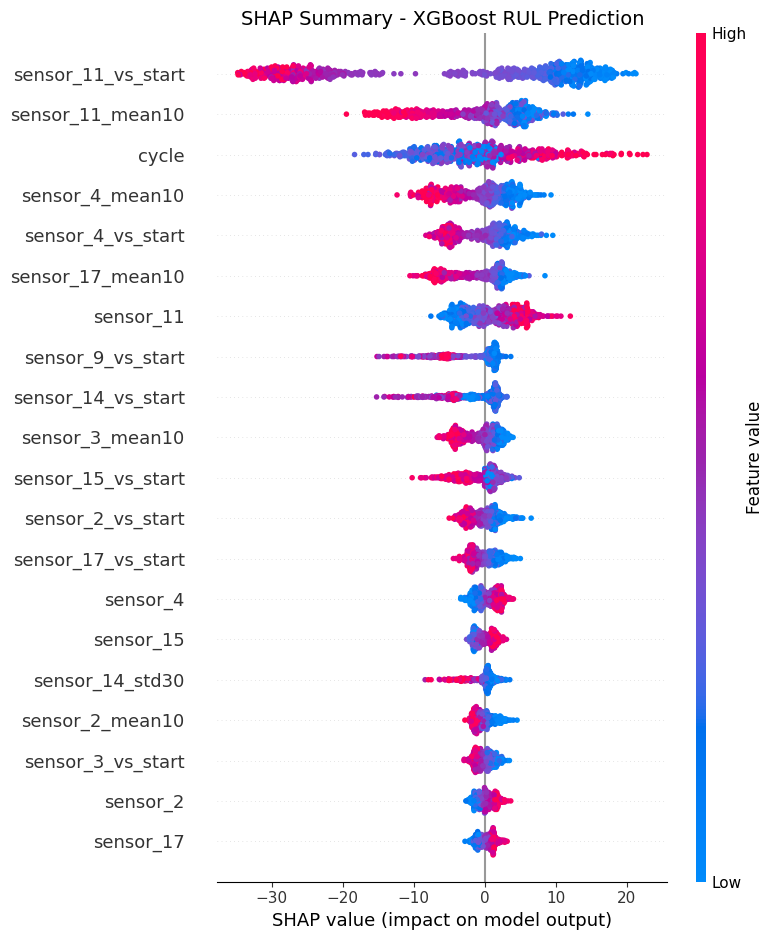

In [147]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values.values,
    X_shap,
    feature_names=rul_feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary - XGBoost RUL Prediction",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "/content/aircraft_engine_ai/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [148]:
shap_importance = pd.DataFrame({
    "Feature": rul_feature_names,
    "Mean_Absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("TOP 20 IMPORTANT FEATURES")

display(shap_importance.head(20))

shap_importance.to_csv(
    "/content/aircraft_engine_ai/shap_feature_importance.csv",
    index=False
)

TOP 20 IMPORTANT FEATURES


,Feature,Mean_Absolute_SHAP
0,sensor_11_vs_start,16.499395
1,sensor_11_mean10,5.718500
2,cycle,5.653859
3,sensor_4_mean10,3.769943
4,sensor_4_vs_start,3.452368
5,sensor_17_mean10,3.447919
6,sensor_11,3.342722
7,sensor_9_vs_start,2.904725
8,sensor_14_vs_start,2.827841
9,sensor_3_mean10,2.171594



Dataset: FD001
Engine: FD001_1
Predicted RUL: 119.97


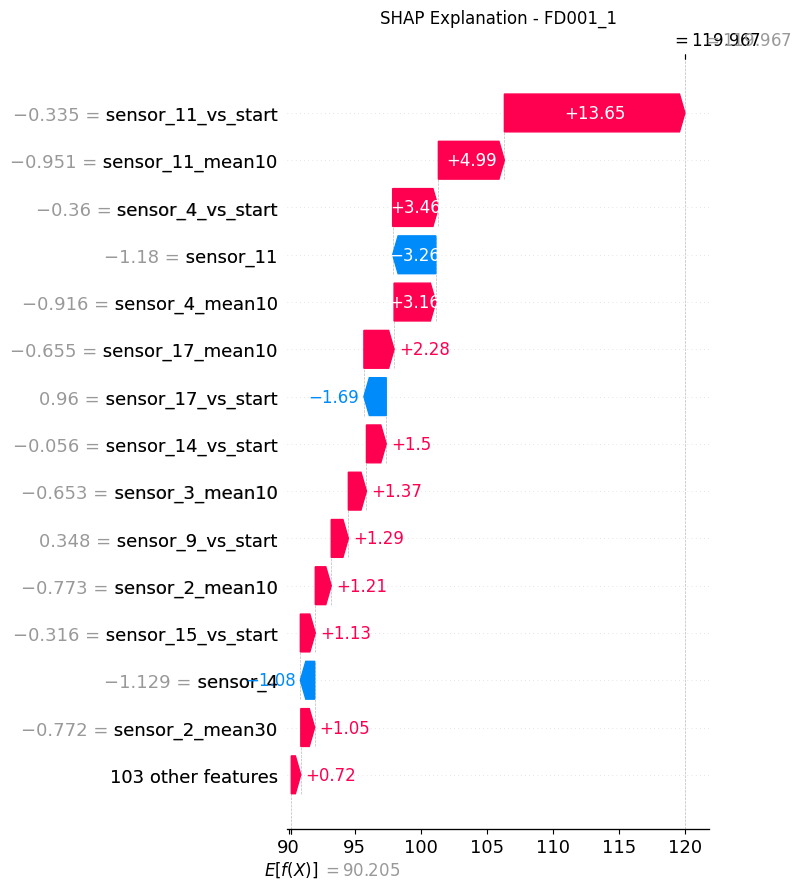


Dataset: FD002
Engine: FD002_1
Predicted RUL: 16.12


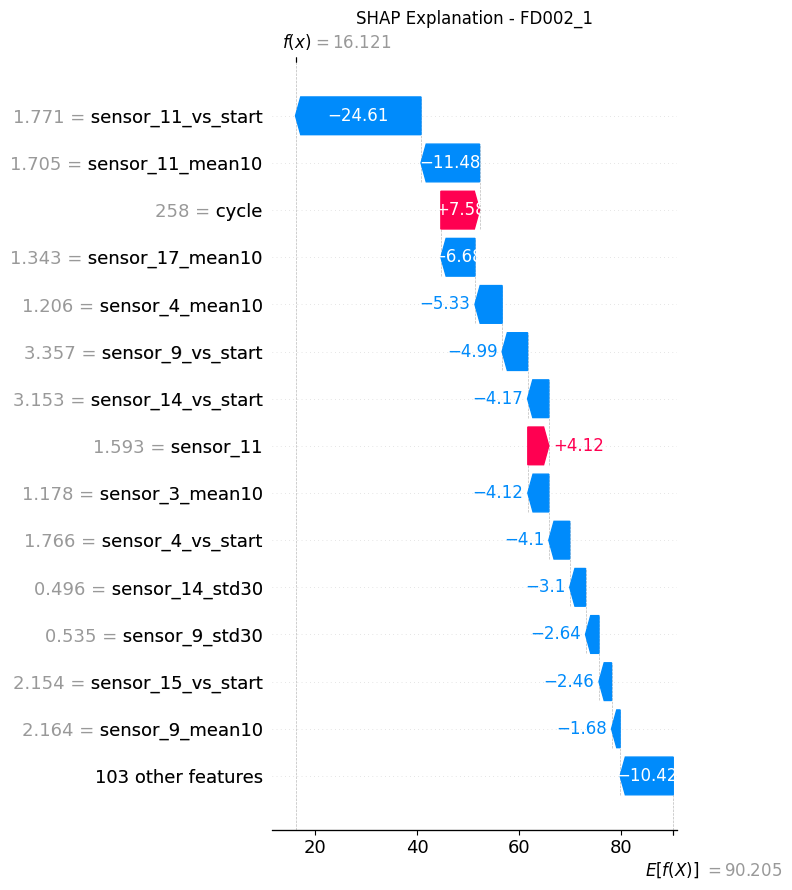


Dataset: FD003
Engine: FD003_1
Predicted RUL: 47.74


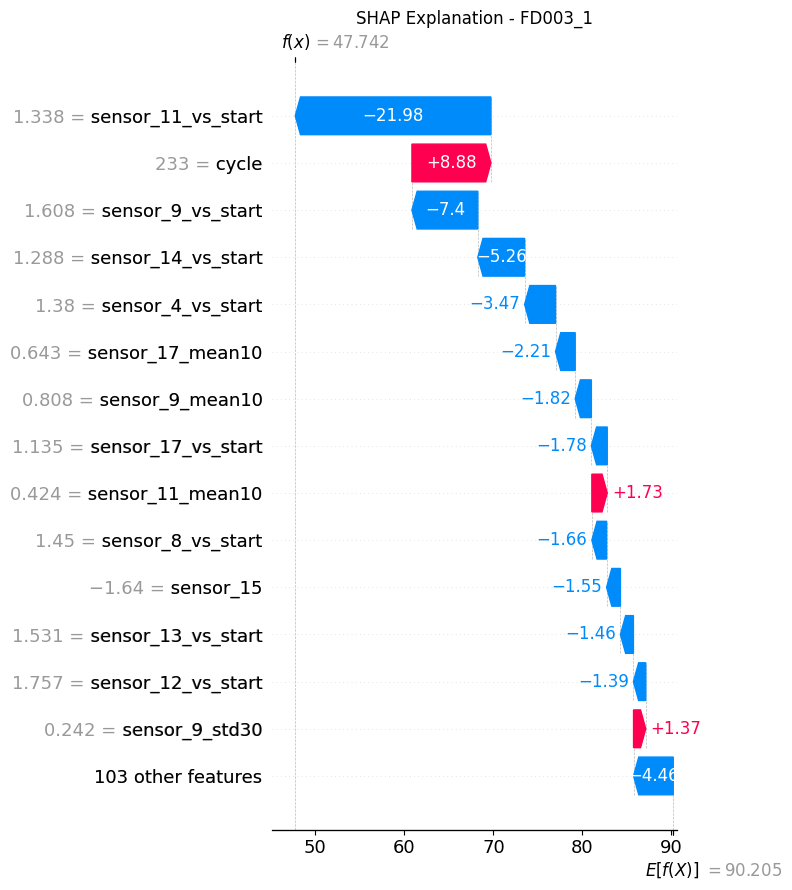


Dataset: FD004
Engine: FD004_1
Predicted RUL: 25.33


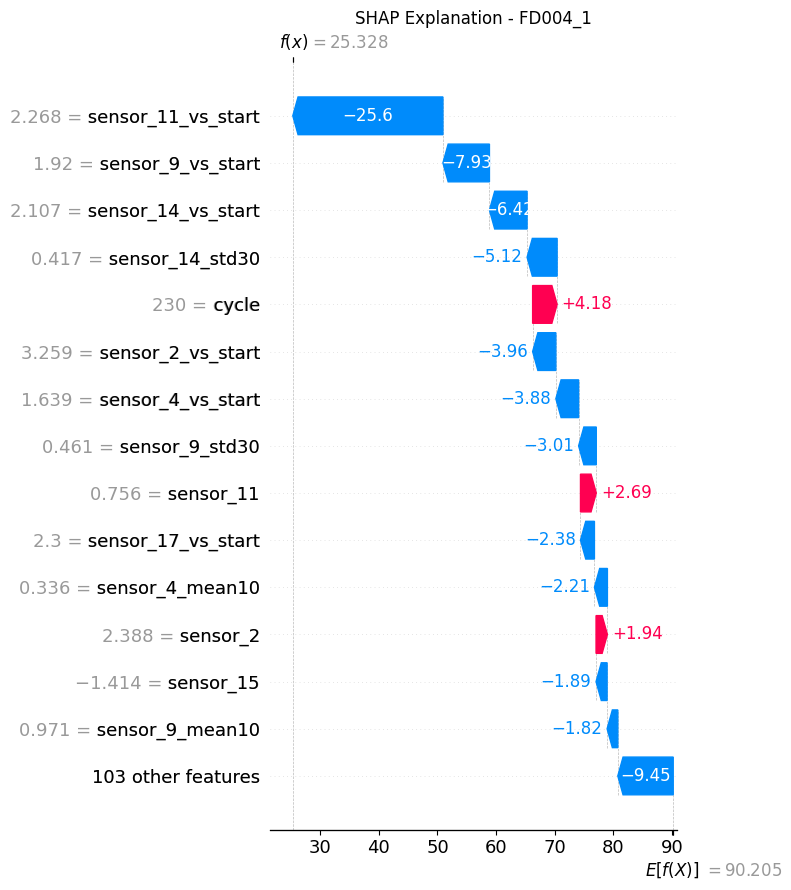


All 4 SHAP Waterfall Plots saved!


In [155]:
save_dir = Path("/content/aircraft_engine_ai")
save_dir.mkdir(parents=True, exist_ok=True)

subsets = ["FD001", "FD002", "FD003", "FD004"]

for subset in subsets:

    # Select one engine from each dataset
    engine_index = rul_results.index[
        rul_results["subset"] == subset
    ][0]

    engine_id = rul_results.loc[
        engine_index, "engine_id"
    ]

    predicted_rul_value = shap_predictions[engine_index]

    print(f"\nDataset: {subset}")
    print(f"Engine: {engine_id}")
    print(f"Predicted RUL: {predicted_rul_value:.2f}")

    shap.plots.waterfall(
        shap_values[engine_index],
        max_display=15,
        show=False
    )

    plt.title(
        f"SHAP Explanation - {engine_id}"
    )

    plt.tight_layout()

    plt.savefig(
        save_dir / f"shap_waterfall_{subset}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nAll 4 SHAP Waterfall Plots saved!")

In [151]:
shap_engine_results = []

for i in range(len(X_shap)):

    contributions = shap_values.values[i]

    top_indices = np.argsort(
        np.abs(contributions)
    )[::-1][:5]

    top_features = []

    for idx in top_indices:

        top_features.append({
            "feature": rul_feature_names[idx],
            "shap_value": round(
                float(contributions[idx]), 4
            ),
            "feature_value": round(
                float(X_shap.iloc[i, idx]), 4
            ),
            "effect": (
                "Increases RUL"
                if contributions[idx] > 0
                else "Decreases RUL"
                if contributions[idx] < 0
                else "No effect"
            )
        })

    shap_engine_results.append({
        "engine_id": rul_results.iloc[i]["engine_id"],
        "predicted_rul": round(
            float(shap_predictions[i]), 2
        ),
        "top_features": top_features
    })

print("SHAP explanations generated:", len(shap_engine_results))

print("\nExample:")
print(shap_engine_results[0])

SHAP explanations generated: 707

Example:
{'engine_id': 'FD001_1', 'predicted_rul': 119.97, 'top_features': [{'feature': 'sensor_11_vs_start', 'shap_value': 13.6498, 'feature_value': -0.3347, 'effect': 'Increases RUL'}, {'feature': 'sensor_11_mean10', 'shap_value': 4.9912, 'feature_value': -0.9509, 'effect': 'Increases RUL'}, {'feature': 'sensor_4_vs_start', 'shap_value': 3.4554, 'feature_value': -0.3596, 'effect': 'Increases RUL'}, {'feature': 'sensor_11', 'shap_value': -3.2631, 'feature_value': -1.1802, 'effect': 'Decreases RUL'}, {'feature': 'sensor_4_mean10', 'shap_value': 3.1561, 'feature_value': -0.9158, 'effect': 'Increases RUL'}]}
